<a href="https://colab.research.google.com/github/nicolastibata/MINE_4210_ADL_202620/blob/main/assingments/assingment_4/MINE_4210_ADL_202620_T4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![Logo ADL](https://github.com/nicolastibata/MINE_4210_ADL_202620/blob/main/docs/logo.png?raw=true)


# **Taller 4: Modelos generativos para imágenes de células sanguíneas**

### **Contexto y Objetivos**

En el laboratorio clínico el recuento diferencial de células en un frotis de sangre periférica orienta el diagnóstico de infecciones, anemias y enfermedades hematológicas. Hacerlo manualmente toma tiempo y sus resultados varían entre observadores, por lo que muchos laboratorios utilizan clasificadores automáticos de imágenes.

Un laboratorio de hematología de un hospital quiere entrenar su propio clasificador, pero tiene solo 200 imágenes de basófilos, una célula poco frecuente en las muestras. Un miembro del equipo propone usar modelos generativos para producir imágenes sintéticas de basófilos, con el fin de complementar los datos de entrenamiento. Esto permitiría, además, compartir imágenes sintéticas en lugar de las reales con otras instituciones, para proteger la información de los pacientes. Antes de decidir, se quiere hacer una evaluación técnica que permita responder a tres inquietudes: ¿las imágenes generadas son realistas y variadas?, ¿el modelo reproduce imágenes reales de pacientes? ¿las imágenes sintéticas mejoran el clasificador?

En este taller compararán un VAE y un modelo de difusión para generar imágenes de basófilos, y evaluarán si las imágenes sintéticas mejoran un clasificador.

Conjunto de datos. Se utilizará BloodMNIST  (https://medmnist.com/). Este dataset está compuesto por 17.092 imágenes de células de sangre periférica, en color y de 28×28 píxeles, clasificadas en 8 tipos (0: basófilo, 1: eosinófilo, 2: eritroblasto, 3: granulocito inmaduro, 4: linfocito, 5: monocito, 6: neutrófilo, 7: plaqueta). Las imágenes originales se adquirieron en el Hospital Clínic de Barcelona, a partir de personas sin infecciones, enfermedades hematológicas u oncológicas, ni tratamiento farmacológico.

Debido al protocolo de recolección de las imágenes, los basófilos representan cerca del 7 % del conjunto, una proporción superior a la práctica clínica. Para simular la situación real del laboratorio, entrenarán los generadores únicamente con 200 basófilos de la partición oficial de entrenamiento. Seleccionen el subconjunto de la siguiente forma:

```python
import numpy as np
from medmnist import BloodMNIST

train = BloodMNIST(split="train", download=True)
val   = BloodMNIST(split="val",   download=True)
test  = BloodMNIST(split="test",  download=True)

idx_baso = np.where(train.labels.ravel() == 0)[0]
rng = np.random.default_rng(42)
idx_sub = rng.choice(idx_baso, size=200, replace=False)
basofilos_train = train.imgs[idx_sub]   # (200, 28, 28, 3)
```

Llamaremos N al número total de basófilos en la partición de entrenamiento. El subconjunto de 200 forma parte de ellos. Para los modelos generativos, normalicen los píxeles al rango [−1, 1]. El conjunto se usa con fines académicos, y los resultados no deben interpretarse como evidencia sobre la utilidad clínica de los modelos. Con base en el tipo de licencia de este conjunto de imágenes deben hacer la citación que corresponde.

<br>

**Actividades**

**1. Exploración y clasificador de referencia.**

- Revisen la distribución de clases en entrenamiento, validación y prueba, y reporten N.
- Muestren seis imágenes reales por clase. ¿Qué distingue visualmente a los basófilos y con cuáles podrían confundirse?
- Construyan un conjunto de entrenamiento que contenga únicamente los 200 basófilos seleccionados y todas las imágenes de entrenamiento de las otras siete clases. Entrenen una CNN con este conjunto, utilizando la siguiente arquitectura:
  ```python
  Conv2D(32, 3×3, ReLU) + MaxPooling(2×2)
  Conv2D(64, 3×3, ReLU) + MaxPooling(2×2)
  Flatten + Dense(128, ReLU) + Dropout(0.3)
  Dense(8, softmax)
  ```
Utilicen Adam (learning rate = 1e-3), máximo 10 épocas y EarlyStopping sobre val_loss (patience=3, restaurando los mejores pesos). Reporten, en el conjunto de test, el F1 macro, y el F1_score y el recall de la clase basófilo.

Conserven el clasificador entrenado y sus resultados, ya que se utilizarán como referencia para evaluar las imágenes generadas y determinar, en la actividad 4, si el aumento sintético mejora la clasificación.

<br>

**2. Generación de imágenes con VAE y DDPM.**

Entrenen ambos modelos exclusivamente con los mismos 200 basófilos. Pueden partir de los ejemplos del laboratorio demostrativo (Laboratorio 10).

**2.1. Modelo 1. VAE**

- Encoder y decoder convolucionales (28 → 14 → 7 y reconstrucción hasta 28 × 28), adaptados a tres canales RGB.
- Espacio latente de dimensión 16; pérdida de reconstrucción más divergencia KL. Documenten su implementación.
- Máximo 300 épocas o 20 minutos de GPU, lo que ocurra primero. Presenten la evolución de las pérdidas.

**2.2 Modelo 2. Modelo de difusión (DDPM)**

Implementen un modelo de difusión utilizando la librería diffusers de Hugging Face. Utilicen la siguiente configuración:

- Arquitectura: UNet2DModel, adaptada a imágenes RGB de 28 × 28 píxeles.
- Proceso de difusión: DDPMScheduler con 1000 pasos de entrenamiento.
- Función de pérdida: error cuadrático medio entre el ruido añadido a las imágenes y el ruido predicho por la U-Net.
- Optimizador: AdamW, con tasa de aprendizaje 1e-4 y tamaño de lote máximo de 64.
- Entrenamiento: máximo de 60 minutos de GPU.

Registren la evolución de la pérdida y documenten la arquitectura utilizada, el número de actualizaciones de los parámetros y el tiempo de entrenamiento.

No se exige alcanzar una calidad visual específica. Si las imágenes tienen defectos, analícenlos y discútanlos. Los 1000 pasos del scheduler describen el proceso de difusión y no equivalen a 1000 actualizaciones de parámetros.

**2.3 Generación**

Generen 300 imágenes sintéticas con cada modelo. Para DDPM indiquen el número de pasos de inferencia utilizado. Conserven los modelos y las imágenes para las actividades siguientes.

<br>

**3. Evaluación de las imágenes generadas**.

| Aspecto | Evaluación |
|-|-|
| Calidad visual y consistencia con la clase | Muestren 16 imágenes por generador y 16 basófilos reales del conjunto de test. Calculen el porcentaje de las 300 sintéticas clasificadas como basófilos por la CNN <br> y compárenlo con su recall sobre basófilos reales de test. | Distribución de longitudes en tokens, distribución de clases y análisis de longitud por ODS. |
| Diversidad | Distancia euclidiana promedio entre pares de 100 imágenes sintéticas por modelo y 100 basófilos reales de test, complementada con inspección visual. |
| Posible memorización | Para cada imagen sintética, busquen el vecino más cercano entre los 200 basófilos de entrenamiento. Muestren los cinco pares más similares por modelo <br> y comparen sus distancias con las de basófilos reales de test frente a esos mismos 200 ejemplos. |

Antes de calcular distancias, lleven las imágenes reales y las sintéticas a la misma escala de valores (por ejemplo, [0, 1]). Con base en estos resultados, elijan el generador que usarán para el aumento sintético y justifiquen la decisión.

<br>

**4. Evaluaciones en el clasificador**. En la actividad 1 entrenaron una CNN utilizando 200 basófilos reales y todas las imágenes de las otras siete clases. Ahora evaluarán si incorporar imágenes sintéticas permite mejorar su desempeño. Para ello:

- Para la construcción de un clasificador con sobre muestreo. Preparen un conjunto de entrenamiento con todas las imágenes de las otras siete clases utilizadas en la actividad 1 y los 200 basófilos reales repetidos hasta completar N (por ejemplo, con np.resize(idx_sub, N)).
- Para la construcción de un clasificador con aumento sintético. Preparen un conjunto de entrenamiento con los 200 basófilos reales, todas las imágenes de las otras siete clases y (N − 200) imágenes sintéticas producidas por el generador seleccionado en la actividad 3, hasta completar N basófilos. Si necesitan más de las 300 imágenes generadas inicialmente, produzcan las adicionales con el mismo modelo. Apliquen a las imágenes sintéticas el mismo formato y preprocesamiento utilizado para entrenar la CNN.
- Entrenen una CNN con cada conjunto, utilizando la misma arquitectura, configuración de entrenamiento y semilla de la actividad 1.
- Evalúen ambas CNN sobre la misma partición oficial de test utilizada en la actividad 1. Presenten en una tabla el F1 macro, y el F1_score y el recall de la clase basófilo de los tres clasificadores (referencia, sobre muestreo y aumento sintético), junto con sus matrices de confusión.

<br>

**5. Análisis**. A partir de los resultados obtenidos, respondan las siguientes preguntas:

1. Comparación de los modelos generativos. ¿Qué diferencias encuentran entre el VAE y el DDPM en términos de calidad visual, diversidad, posible memorización  y costo de generación? ¿Cómo se relacionan estas diferencias con el funcionamiento de ambos modelos? ¿Qué limitaciones tienen las métricas utilizadas para evaluar las imágenes, considerando además que la CNN evaluadora se entrenó con los mismos 200 basófilos que usaron los generadores?
2. Utilidad de las imágenes sintéticas. ¿La incorporación de imágenes sintéticas mejoró el desempeño del clasificador frente al entrenado únicamente con imágenes reales y, sobre todo, frente al entrenado con sobre muestreo? ¿Qué relación encuentran entre los resultados de clasificación y la calidad y diversidad de las imágenes generadas? Dado que cada clasificador se entrenó con una sola semilla, ¿qué tan confiables son las diferencias observadas? ¿Qué limitaciones tiene este experimento para determinar si las imágenes sintéticas aportan información nueva?
3. Recomendación al laboratorio. En una nota de máximo 300 palabras, indiquen si recomiendan utilizar imágenes sintéticas para complementar los datos de entrenamiento y si consideran adecuado compartirlas con otras instituciones en lugar de las imágenes reales. Justifiquen sus recomendaciones con base en los resultados obtenidos y señalen las limitaciones y la evidencia adicional que sería necesaria antes de aplicar estas soluciones en un entorno clínico.

**Bono (hasta 15 % adicional).** A partir del código del laboratorio, entrenen una GAN con los mismos 200 basófilos (Adam, learning rate 2e-4, betas=(0.5, 0.999), máximo 20 minutos de GPU). Generen 300 imágenes y comparen calidad visual, consistencia con la clase y diversidad con VAE y DDPM mediante los procedimientos correspondientes de la actividad 3. ¿Hay indicios de colapso de modos? ¿Qué evidencia los respalda? ¿Cambiarían la elección del generador?

### **Entregable**

Notebook (.ipynb) con todas las celdas ejecutadas, organizado por actividades, que incluya código, tablas, visualizaciones, análisis, nota al laboratorio,  referencias a recursos externos y con todas las indicaciones anteriormente estipuladas en la sección de laboratorios en **Bloque Neón**. Documenten decisiones y permitan reproducir los experimentos en la medida de lo posible.



### **Rúbrica**

| Criterio | Peso | Qué se evalúa |
|-|-|-|
| 1. Exploración y clasificador de referencia | 15 % | Exploración y distribución de clases, selección de los 200 basófilos, entrenamiento de la CNN y evaluación mediante las métricas solicitadas. |
| 2. Generación de imágenes con VAE y DDPM | 30 % | Implementación y entrenamiento de ambos modelos, documentación de configuraciones y pérdidas, y generación de 300 imágenes por modelo con su tiempo de generación. |
| 3. Evaluación de las imágenes generadas | 20 % | Evaluación comparativa de calidad visual, consistencia con la clase, diversidad y posible memorización; interpretación y selección justificada del generador. |
| 4. Evaluación en el clasificador | 15 % | Preparación de los conjuntos con sobre muestreo y con aumento sintético, entrenamiento de las dos CNN y comparación de su desempeño con el clasificador de referencia. |
| 5. Análisis | 20 % | Comparación de los generadores, interpretación de la utilidad del aumento sintético frente al sobre muestreo, discusión de limitaciones y recomendación sustentada al laboratorio. |
| 6. Bono. GAN | +15 % | Entrenamiento de la GAN, generación y evaluación de imágenes, comparación con VAE y DDPM, análisis de posible colapso de modos y justificación de la elección del generador. |

> *Uso de IAG en la elaboración del enunciado de este laboratorio.
El equipo docente declara de forma explícita que, en el contexto de este laboratorio, la IAG fue utilizada como apoyo en la búsqueda del conjunto de datos y en la redacción del enunciado. Todo el contenido fue revisado, verificado y ajustado por el equipo docente.*


# Solución persona 1 — actividades 1, 2.1, 2.2 y 2.3

Se conserva intacto el enunciado y la rúbrica originales. Esta sección implementa únicamente la exploración, la CNN de referencia, el VAE, el DDPM y la generación de 300 imágenes por modelo; no resuelve las actividades 3–5 ni el bono. Las imágenes se descargan en las particiones oficiales de MedMNIST; ambos generadores se ajustan solo con los mismos 200 basófilos de entrenamiento. Las métricas son académicas y no constituyen evidencia de utilidad clínica.

## 1. Exploración y clasificador de referencia

La selección se reproduce literalmente con `default_rng(42)` sobre la partición oficial `train`. La CNN recibe esos 200 basófilos y todas las imágenes de las otras siete clases; validación y prueba permanecen en sus particiones oficiales.

## Continuación persona 2 — ejecución no destructiva

A partir de aquí se reutilizan los checkpoints y los 300 PNG de persona 1. Para cumplir la restricción de no modificar `artefactos/persona1/`, las celdas de persona 1 redirigen sus gráficas y archivos recalculados a `artefactos/persona2/auditoria/`, verifican `idx_sub.npy` en lugar de reescribirlo y cargan las imágenes heredadas en vez de regenerarlas. Esto no cambia arquitecturas, pesos ni métricas; solo evita sobrescribir entregables ajenos. La ejecución se hace siempre con directorio de trabajo `Taller 4` porque el notebook usa `Path.cwd()`.


Python: 3.14.10 | PyTorch: 2.15.0+cu132
Dispositivo detectado: cuda
GPU: NVIDIA GeForce RTX 2070


N = 852 basófilos en train; seleccionados = 200
Forma seleccionada: (200, 28, 28, 3); rango RGB: [0, 255]


,Basófilo,Eosinófilo,Eritroblasto,Granulocito inmaduro,Linfocito,Monocito,Neutrófilo,Plaqueta
Partición oficial,,,,,,,,
train,852,2181,1085,2026,849,993,2330,1643
val,122,312,155,290,122,143,333,235
test,244,624,311,579,243,284,666,470


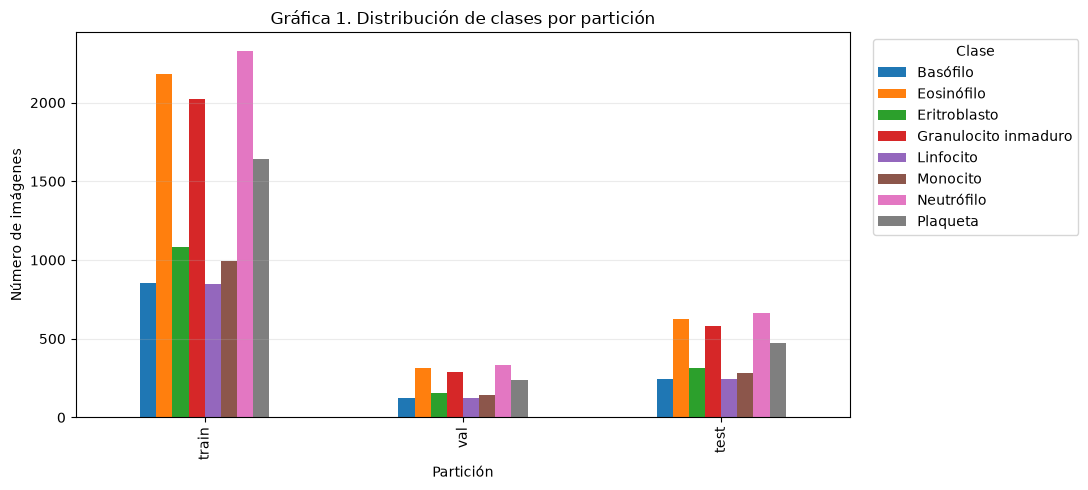

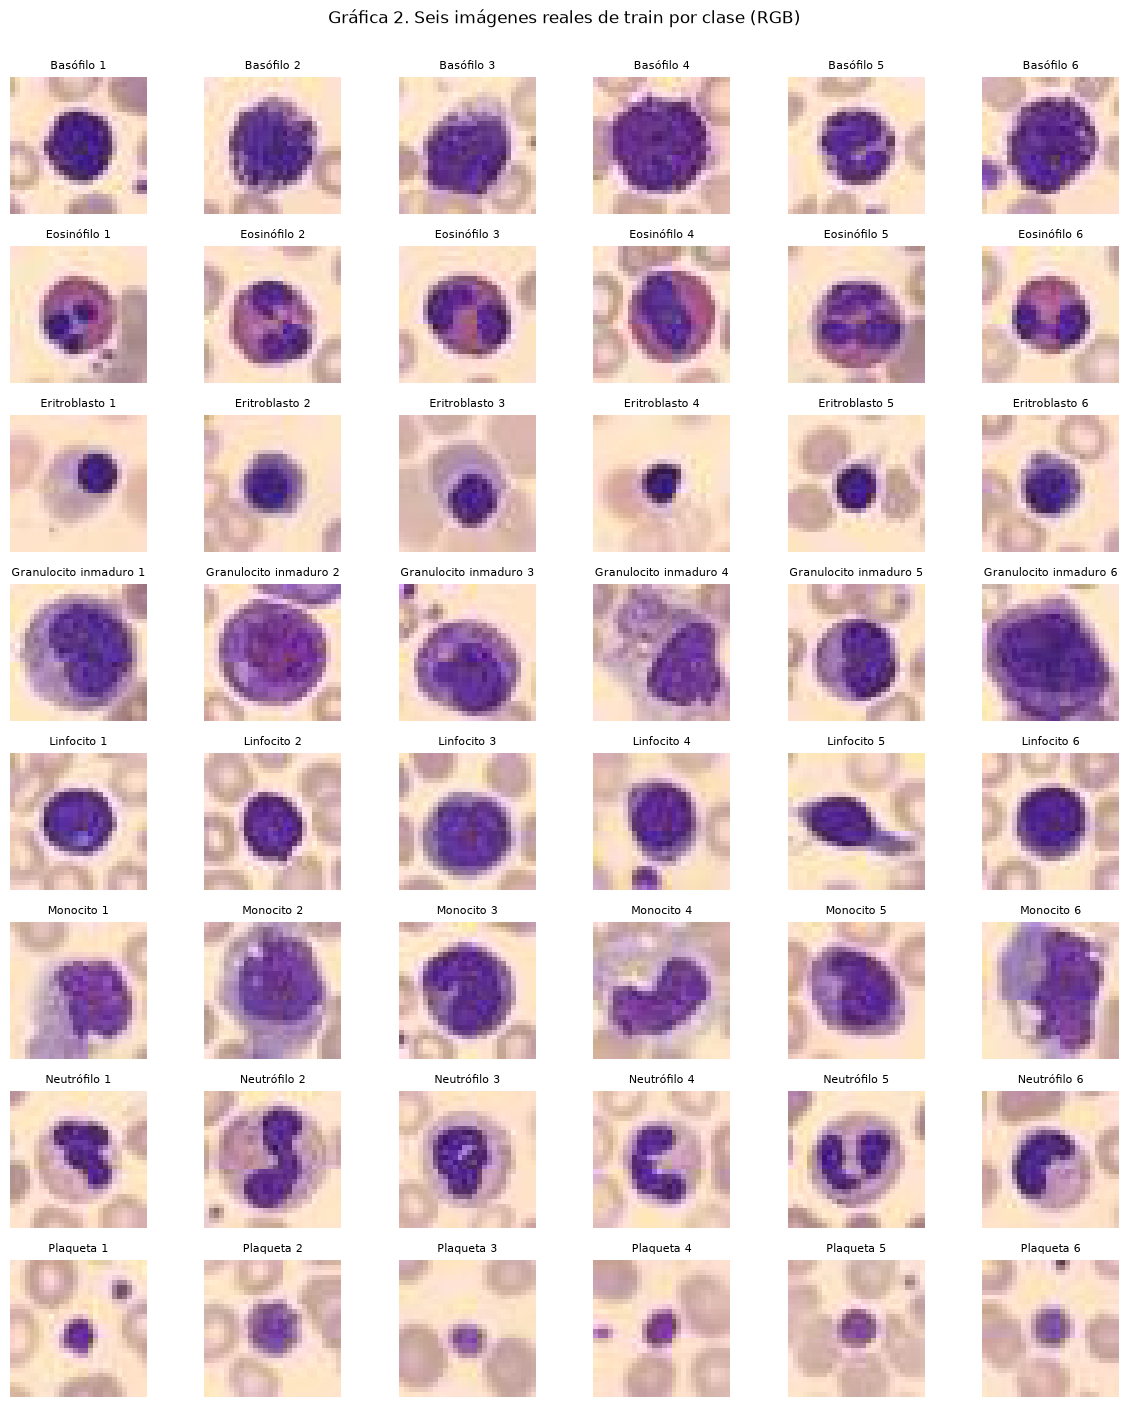

Conteos de ocho clases y cuadrícula de 48 imágenes reales generados.


In [1]:
from pathlib import Path
import json
import random
import time
import copy
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import f1_score, recall_score
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from medmnist import BloodMNIST
from diffusers import UNet2DModel, DDPMScheduler

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMILLA)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python: {__import__('sys').version.split()[0]} | PyTorch: {torch.__version__}")
print(f"Dispositivo detectado: {DISPOSITIVO}")
if DISPOSITIVO.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

RAIZ = Path.cwd()
ARTEFACTOS = RAIZ / "artefactos" / "persona1"
ARTEFACTOS_P2 = RAIZ / "artefactos" / "persona2"
RAIZ_AUDITORIA = ARTEFACTOS_P2 / "auditoria"
RAIZ_AUDITORIA.mkdir(parents=True, exist_ok=True)
GRAFICAS = RAIZ_AUDITORIA
CNN_PATH = ARTEFACTOS / "cnn_referencia.pt"
VAE_PATH = ARTEFACTOS / "vae.pt"
DDPM_DIR = ARTEFACTOS / "ddpm"
for carpeta in (ARTEFACTOS, GRAFICAS, ARTEFACTOS / "vae_imagenes", ARTEFACTOS / "ddpm_imagenes"):
    carpeta.mkdir(parents=True, exist_ok=True)

NOMBRES_CLASES = [
    "Basófilo", "Eosinófilo", "Eritroblasto", "Granulocito inmaduro",
    "Linfocito", "Monocito", "Neutrófilo", "Plaqueta",
]
train = BloodMNIST(split="train", download=True)
val = BloodMNIST(split="val", download=True)
test = BloodMNIST(split="test", download=True)

# Selección oficial exacta; se guarda para reproducir los índices más adelante.
idx_baso = np.where(train.labels.ravel() == 0)[0]
N = len(idx_baso)
rng = np.random.default_rng(42)
idx_sub = rng.choice(idx_baso, size=200, replace=False)
basofilos_train = train.imgs[idx_sub]
assert np.array_equal(np.load(ARTEFACTOS / "idx_sub.npy"), idx_sub)
assert N >= 200 and len(np.unique(idx_sub)) == 200
assert np.all(train.labels.ravel()[idx_sub] == 0)
assert basofilos_train.shape == (200, 28, 28, 3)
print(f"N = {N} basófilos en train; seleccionados = {len(idx_sub)}")
print(f"Forma seleccionada: {basofilos_train.shape}; rango RGB: [{basofilos_train.min()}, {basofilos_train.max()}]")

particiones = {"train": train, "val": val, "test": test}
conteos = pd.DataFrame(
    {nombre: np.bincount(datos.labels.ravel(), minlength=8) for nombre, datos in particiones.items()},
    index=NOMBRES_CLASES,
).T
conteos.index.name = "Partición oficial"
display(conteos)

fig, ax = plt.subplots(figsize=(11, 5))
conteos.plot(kind="bar", ax=ax)
ax.set(title="Gráfica 1. Distribución de clases por partición", xlabel="Partición", ylabel="Número de imágenes")
ax.legend(title="Clase", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(GRAFICAS / "distribucion_clases.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(8, 6, figsize=(12, 14))
for clase, ax_row in enumerate(axes):
    indices_clase = np.flatnonzero(train.labels.ravel() == clase)[:6]
    for muestra, (ax, indice) in enumerate(zip(ax_row, indices_clase), start=1):
        ax.imshow(train.imgs[indice])
        ax.set_title(f"{NOMBRES_CLASES[clase]} {muestra}", fontsize=8)
        ax.axis("off")
fig.suptitle("Gráfica 2. Seis imágenes reales de train por clase (RGB)", y=1.002)
fig.tight_layout()
fig.savefig(GRAFICAS / "muestras_reales_48.png", dpi=150, bbox_inches="tight")
plt.show()

print("Conteos de ocho clases y cuadrícula de 48 imágenes reales generados.")

### Inspección visual

En las imágenes de 28×28 observadas, los basófilos muestran principalmente un núcleo central oscuro violáceo y el detalle citoplasmático es limitado. Por su núcleo redondeado y oscuro pueden confundirse visualmente con linfocitos y algunos granulocitos inmaduros. La baja resolución y seis ejemplos por clase limitan esta apreciación.

### CNN de referencia

Las convoluciones válidas y el pooling producen mapas de 13×13 y luego 5×5; la capa densa termina en ocho logits. Estos logits son equivalentes a una salida softmax cuando se usan con `CrossEntropyLoss`, que incorpora la normalización log-softmax. Se entrena con Adam, tasa `1e-3`, hasta 10 épocas y parada temprana sobre `val_loss` (`patience=3`), restaurando el estado con menor pérdida de validación.

CNN recuperada de /home/juanes/Tareas/9 Semestre/Analisis Deep learning/Talleres/Taller 4/artefactos/persona1/cnn_referencia.pt; no se reentrena.


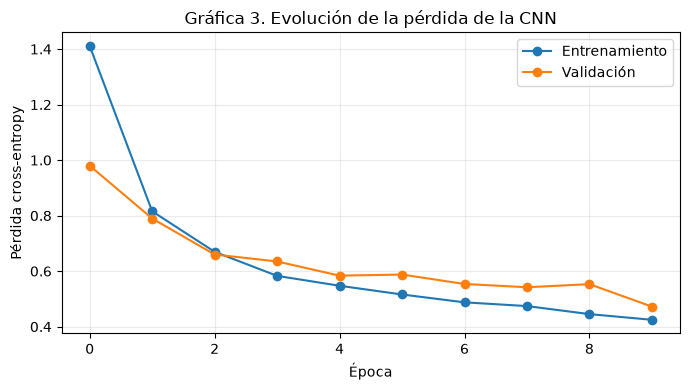

                                f1_macro  f1_basofilo  recall_basofilo  epocas  mejor_val_loss
CNN referencia en test oficial  0.769993     0.331081          0.20082      10        0.472257
Checkpoint CNN recargado sin reentrenar y evaluado con un lote: verificado.


CNNReferencia(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1600, out_features=128, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=8, bias=True)
)

In [2]:
class CNNReferencia(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64 * 5 * 5, 128)
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(128, 8)

    def forward(self, imagenes):
        x = self.pool(F.relu(self.conv1(imagenes)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, start_dim=1)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.fc2(x)

def cargar_cnn_referencia(ruta=CNN_PATH, device=DISPOSITIVO):
    checkpoint = torch.load(ruta, map_location="cpu", weights_only=True)
    modelo = CNNReferencia().to(device)
    modelo.load_state_dict(checkpoint["state_dict"])
    return modelo.eval(), checkpoint

def imagenes_a_tensor(imagenes, rango="cero_uno"):
    tensor = torch.as_tensor(np.asarray(imagenes), dtype=torch.float32).permute(0, 3, 1, 2)
    if rango == "cero_uno":
        tensor = tensor / 255.0
    elif rango == "menos_uno_uno":
        tensor = tensor / 127.5 - 1.0
    else:
        raise ValueError(f"Rango desconocido: {rango}")
    return tensor

labels_train = train.labels.ravel()
idx_otros = np.flatnonzero(labels_train != 0)
idx_cnn = np.concatenate((idx_sub, idx_otros))
x_cnn = imagenes_a_tensor(train.imgs[idx_cnn], "cero_uno")
y_cnn = torch.as_tensor(labels_train[idx_cnn], dtype=torch.long)
x_val = imagenes_a_tensor(val.imgs, "cero_uno")
y_val = torch.as_tensor(val.labels.ravel(), dtype=torch.long)
x_test = imagenes_a_tensor(test.imgs, "cero_uno")
y_test = torch.as_tensor(test.labels.ravel(), dtype=torch.long)
assert int((y_cnn == 0).sum()) == 200
assert len(y_cnn) == 200 + int((labels_train != 0).sum())

cnn_config = {
    "semilla": SEMILLA, "entrada": [3, 28, 28], "normalizacion": "RGB [0,255] -> [0,1]",
    "arquitectura": "Conv2d(3,32,3)-ReLU-MaxPool2d(2), Conv2d(32,64,3)-ReLU-MaxPool2d(2), Flatten, Linear(1600,128)-ReLU-Dropout(0.3), Linear(128,8) logits",
    "optimizador": "Adam", "learning_rate": 1e-3, "batch_size": 128,
    "max_epocas": 10, "early_stopping": {"monitor": "val_loss", "patience": 3, "restaurar_mejores_pesos": True},
    "n_basofilos_entrenamiento": 200, "n_otros_entrenamiento": int(len(idx_otros)),
}

if CNN_PATH.exists():
    cnn_checkpoint = torch.load(CNN_PATH, map_location="cpu", weights_only=True)
    modelo_cnn = CNNReferencia().to(DISPOSITIVO)
    modelo_cnn.load_state_dict(cnn_checkpoint["state_dict"])
    cnn_historial = cnn_checkpoint["historial"]
    epocas_cnn = cnn_checkpoint["epocas"]
    print(f"CNN recuperada de {CNN_PATH}; no se reentrena.")
else:
    torch.manual_seed(SEMILLA)
    generador_loader = torch.Generator().manual_seed(SEMILLA)
    loader_train = DataLoader(TensorDataset(x_cnn, y_cnn), batch_size=128, shuffle=True, generator=generador_loader)
    loader_val = DataLoader(TensorDataset(x_val, y_val), batch_size=256, shuffle=False)
    modelo_cnn = CNNReferencia().to(DISPOSITIVO)
    optimizador_cnn = torch.optim.Adam(modelo_cnn.parameters(), lr=1e-3)
    cnn_historial = {"train_loss": [], "val_loss": []}
    mejor_val = float("inf")
    mejores_pesos = None
    epocas_sin_mejora = 0
    for epoca in range(10):
        modelo_cnn.train()
        suma_train = 0.0
        for xb, yb in loader_train:
            xb, yb = xb.to(DISPOSITIVO), yb.to(DISPOSITIVO)
            optimizador_cnn.zero_grad(set_to_none=True)
            perdida = F.cross_entropy(modelo_cnn(xb), yb)
            perdida.backward()
            optimizador_cnn.step()
            suma_train += perdida.item() * len(xb)
        modelo_cnn.eval()
        suma_val = 0.0
        with torch.no_grad():
            for xb, yb in loader_val:
                xb, yb = xb.to(DISPOSITIVO), yb.to(DISPOSITIVO)
                suma_val += F.cross_entropy(modelo_cnn(xb), yb, reduction="sum").item()
        train_loss = suma_train / len(loader_train.dataset)
        val_loss = suma_val / len(loader_val.dataset)
        cnn_historial["train_loss"].append(train_loss)
        cnn_historial["val_loss"].append(val_loss)
        print(f"Época {epoca + 1:02d}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}")
        if val_loss < mejor_val:
            mejor_val = val_loss
            mejores_pesos = copy.deepcopy(modelo_cnn.state_dict())
            epocas_sin_mejora = 0
        else:
            epocas_sin_mejora += 1
            if epocas_sin_mejora >= 3:
                print("EarlyStopping: no mejoró val_loss durante 3 épocas.")
                break
    modelo_cnn.load_state_dict(mejores_pesos)
    epocas_cnn = len(cnn_historial["train_loss"])
    torch.save({"state_dict": modelo_cnn.cpu().state_dict(), "historial": cnn_historial, "epocas": epocas_cnn, "config": cnn_config}, CNN_PATH)
    modelo_cnn.to(DISPOSITIVO)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cnn_historial["train_loss"], marker="o", label="Entrenamiento")
ax.plot(cnn_historial["val_loss"], marker="o", label="Validación")
ax.set(title="Gráfica 3. Evolución de la pérdida de la CNN", xlabel="Época", ylabel="Pérdida cross-entropy")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(GRAFICAS / "perdida_cnn.png", dpi=150, bbox_inches="tight")
plt.show()

modelo_cnn.eval()
predicciones = []
with torch.no_grad():
    for inicio in range(0, len(x_test), 256):
        logits = modelo_cnn(x_test[inicio:inicio + 256].to(DISPOSITIVO))
        predicciones.extend(logits.argmax(dim=1).cpu().numpy().tolist())
y_test_np = y_test.numpy()
metricas_cnn = {
    "f1_macro": float(f1_score(y_test_np, predicciones, average="macro", zero_division=0)),
    "f1_basofilo": float(f1_score(y_test_np == 0, np.asarray(predicciones) == 0, zero_division=0)),
    "recall_basofilo": float(recall_score(y_test_np == 0, np.asarray(predicciones) == 0, zero_division=0)),
}
metricas_cnn.update({"epocas": epocas_cnn, "mejor_val_loss": float(min(cnn_historial["val_loss"]))})
print(pd.DataFrame([metricas_cnn], index=["CNN referencia en test oficial"]).to_string())
if not (ARTEFACTOS / "metricas_cnn.json").exists():
    with open(ARTEFACTOS / "metricas_cnn.json", "w", encoding="utf-8") as archivo:
        json.dump({"metricas": metricas_cnn, "y_true": y_test_np.tolist(), "y_pred": predicciones, "historial": cnn_historial, "configuracion": cnn_config}, archivo, ensure_ascii=False, indent=2)
cnn_verificacion, _ = cargar_cnn_referencia()
with torch.no_grad():
    assert cnn_verificacion(x_test[:2].to(DISPOSITIVO)).shape == (2, 8)
print("Checkpoint CNN recargado sin reentrenar y evaluado con un lote: verificado.")
del cnn_verificacion
modelo_cnn.to("cpu")
if DISPOSITIVO.type == "cuda":
    torch.cuda.empty_cache()
modelo_cnn.to(DISPOSITIVO)

## 2.1. VAE convolucional RGB

El encoder reduce 28→14→7 y produce `mu` y `logvar` de dimensión 16; el decoder sube 7→14→28 y su salida `tanh` conserva valores en `[-1,1]`. La reconstrucción y el KL se calculan como sumas por imagen (sobre canales/píxeles y dimensión latente, respectivamente) y luego se promedian entre ejemplos del lote. La CNN usa `[0,1]`; este generador usa exclusivamente los 200 basófilos normalizados a `[-1,1]`.

VAE recuperado de /home/juanes/Tareas/9 Semestre/Analisis Deep learning/Talleres/Taller 4/artefactos/persona1/vae.pt; no se reentrena.


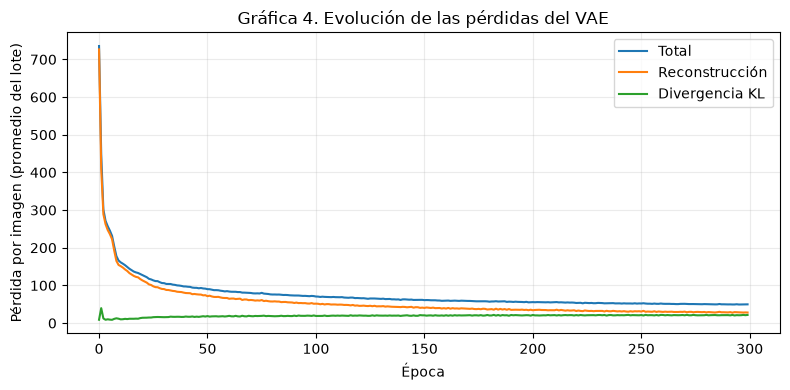

Última época: total=49.78; reconstrucción=28.09; KL=21.69


In [3]:
class VAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1), nn.ReLU(),
        )
        self.fc_mu = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_logvar = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_decode = nn.Linear(latent_dim, 64 * 7 * 7)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 3, kernel_size=3, padding=1), nn.Tanh(),
        )

    def encode(self, x):
        h = self.encoder_conv(x).flatten(start_dim=1)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

    def decode(self, z):
        h = self.fc_decode(z).view(-1, 64, 7, 7)
        return self.decoder(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar

def perdida_vae(reconstruccion, x, mu, logvar):
    reconstruccion_por_imagen = F.mse_loss(reconstruccion, x, reduction="none").flatten(1).sum(dim=1)
    kl_por_imagen = -0.5 * torch.sum(1 + logvar - mu.square() - logvar.exp(), dim=1)
    return (reconstruccion_por_imagen + kl_por_imagen).mean(), reconstruccion_por_imagen.mean(), kl_por_imagen.mean()

def guardar_vae(modelo, ruta, config, historial, segundos, epocas):
    torch.save({"state_dict": modelo.cpu().state_dict(), "config": config, "historial": historial, "tiempo_entrenamiento_segundos": segundos, "epocas": epocas}, ruta)
    modelo.to(DISPOSITIVO)

def cargar_vae(ruta=VAE_PATH, device=DISPOSITIVO):
    datos = torch.load(ruta, map_location="cpu", weights_only=True)
    modelo = VAE(latent_dim=datos["config"]["latent_dim"])
    modelo.load_state_dict(datos["state_dict"])
    return modelo.to(device).eval(), datos

vae_config = {
    "latent_dim": 16, "entrada": [3, 28, 28], "normalizacion": "RGB [0,255] -> [-1,1]",
    "encoder": "Conv2d(3,32,3,stride=2,padding=1)-ReLU; Conv2d(32,64,3,stride=2,padding=1)-ReLU; mu/logvar Linear(3136,16)",
    "decoder": "Linear(16,3136); ConvTranspose2d(64,32,4,stride=2,padding=1); ConvTranspose2d(32,16,4,stride=2,padding=1); Conv2d(16,3,3,padding=1)-tanh",
    "perdida": "media por lote de (MSE sumada por imagen + KL sumada en dimensión latente)",
    "optimizador": "Adam", "learning_rate": 1e-3, "batch_size": 32,
    "max_epocas": 300, "limite_gpu_segundos": 1200, "epocas_maximas_cpu": 30, "semilla": SEMILLA,
}
vae_historial = {"total": [], "reconstruccion": [], "kl": []}
vae_segundos = 0.0
if VAE_PATH.exists():
    modelo_vae, vae_checkpoint = cargar_vae()
    vae_historial = vae_checkpoint["historial"]
    vae_segundos = float(vae_checkpoint["tiempo_entrenamiento_segundos"])
    epocas_vae = int(vae_checkpoint["epocas"])
    print(f"VAE recuperado de {VAE_PATH}; no se reentrena.")
else:
    x_baso = imagenes_a_tensor(basofilos_train, "menos_uno_uno")
    loader_vae = DataLoader(TensorDataset(x_baso), batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(SEMILLA))
    torch.manual_seed(SEMILLA)
    modelo_vae = VAE(16).to(DISPOSITIVO)
    optimizador_vae = torch.optim.Adam(modelo_vae.parameters(), lr=1e-3)
    max_epocas_vae = 300 if DISPOSITIVO.type == "cuda" else 30
    inicio_vae = time.perf_counter()
    epocas_vae = 0
    for epoca in range(max_epocas_vae):
        if DISPOSITIVO.type == "cuda":
            torch.cuda.synchronize()
            if time.perf_counter() - inicio_vae >= 1200:
                break
        modelo_vae.train()
        acumulados = np.zeros(3, dtype=np.float64)
        cantidad = 0
        for (xb,) in loader_vae:
            if DISPOSITIVO.type == "cuda":
                torch.cuda.synchronize()
                if time.perf_counter() - inicio_vae >= 1200:
                    break
            xb = xb.to(DISPOSITIVO)
            optimizador_vae.zero_grad(set_to_none=True)
            reconstruccion, mu, logvar = modelo_vae(xb)
            total, recon, kl = perdida_vae(reconstruccion, xb, mu, logvar)
            total.backward()
            optimizador_vae.step()
            acumulados += np.array([total.item(), recon.item(), kl.item()]) * len(xb)
            cantidad += len(xb)
        if cantidad == 0:
            break
        for llave, valor in zip(("total", "reconstruccion", "kl"), acumulados / cantidad):
            vae_historial[llave].append(float(valor))
        epocas_vae += 1
        if DISPOSITIVO.type == "cuda":
            torch.cuda.synchronize()
        vae_segundos = time.perf_counter() - inicio_vae
        if epoca == 0 or (epoca + 1) % 25 == 0:
            print(f"VAE época {epoca + 1:03d}: total={vae_historial['total'][-1]:.2f}, reconstrucción={vae_historial['reconstruccion'][-1]:.2f}, KL={vae_historial['kl'][-1]:.2f}, tiempo={vae_segundos:.1f}s")
        guardar_vae(modelo_vae, VAE_PATH, vae_config, vae_historial, vae_segundos, epocas_vae)
        if DISPOSITIVO.type == "cuda" and vae_segundos >= 1200:
            break
    if DISPOSITIVO.type == "cuda":
        torch.cuda.synchronize()
        vae_segundos = time.perf_counter() - inicio_vae
    guardar_vae(modelo_vae, VAE_PATH, vae_config, vae_historial, vae_segundos, epocas_vae)
    print(f"VAE finalizado: {epocas_vae} épocas; entrenamiento={vae_segundos:.1f}s ({'GPU' if DISPOSITIVO.type == 'cuda' else 'CPU, sin presupuesto GPU'}).")

fig, ax = plt.subplots(figsize=(8, 4))
for llave, etiqueta in (("total", "Total"), ("reconstruccion", "Reconstrucción"), ("kl", "Divergencia KL")):
    ax.plot(vae_historial[llave], label=etiqueta)
ax.set(title="Gráfica 4. Evolución de las pérdidas del VAE", xlabel="Época", ylabel="Pérdida por imagen (promedio del lote)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(GRAFICAS / "perdidas_vae.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Última época: total={vae_historial['total'][-1]:.2f}; reconstrucción={vae_historial['reconstruccion'][-1]:.2f}; KL={vae_historial['kl'][-1]:.2f}")

## 2.2. DDPM con `diffusers`

La U-Net `UNet2DModel` recibe y predice tensores RGB de 28×28, con dos bloques espaciales compatibles con esta resolución. `DDPMScheduler` usa 1000 pasos de difusión para el ruido y su predicción MSE; AdamW usa `1e-4` y lote 32 (≤64). Las actualizaciones que se informan son llamadas reales a `optimizer.step()`; los 1000 pasos de difusión no son 1000 actualizaciones de parámetros. Se fijó un tope adicional de 300 épocas para acotar la ejecución, sin superar nunca los 60 minutos de GPU. Si el entorno solo ofrece CPU, se ejecutan como máximo 10 épocas y se informa como corrida parcial, sin atribuir tiempo GPU.

DDPM recuperado de /home/juanes/Tareas/9 Semestre/Analisis Deep learning/Talleres/Taller 4/artefactos/persona1/ddpm; no se reentrena.


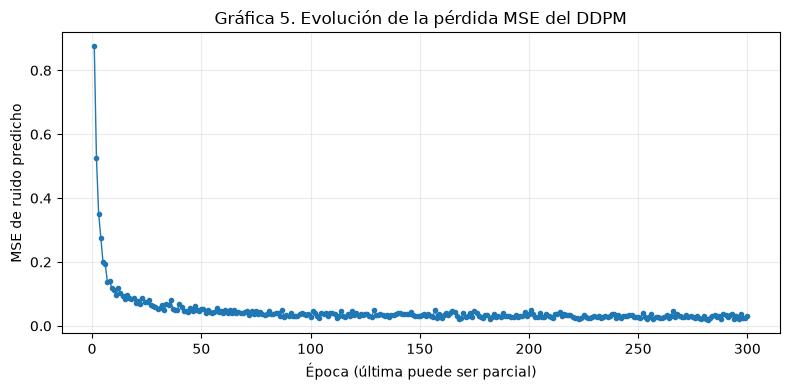

Configuración U-Net: [64, 128] canales por bloque; scheduler train timesteps=1000; batch=32; AdamW lr=1e-4.


In [4]:
ddpm_config = {
    "sample_size": 28, "in_channels": 3, "out_channels": 3,
    "layers_per_block": 1, "block_out_channels": [64, 128],
    "down_block_types": ["DownBlock2D", "AttnDownBlock2D"],
    "up_block_types": ["AttnUpBlock2D", "UpBlock2D"], "norm_num_groups": 32,
    "scheduler": "DDPMScheduler", "num_train_timesteps": 1000,
    "prediccion": "ruido añadido; pérdida MSE", "optimizador": "AdamW",
    "learning_rate": 1e-4, "batch_size": 32, "max_epocas_gpu": 300, "limite_gpu_segundos": 3600,
    "epocas_maximas_cpu": 10, "semilla": SEMILLA,
    "normalizacion": "RGB [0,255] -> [-1,1]",
}

def crear_unet(config=ddpm_config):
    return UNet2DModel(
        sample_size=config["sample_size"], in_channels=config["in_channels"], out_channels=config["out_channels"],
        layers_per_block=config["layers_per_block"], block_out_channels=tuple(config["block_out_channels"]),
        down_block_types=tuple(config["down_block_types"]), up_block_types=tuple(config["up_block_types"]),
        norm_num_groups=config["norm_num_groups"],
    )

def cargar_ddpm(ruta=DDPM_DIR, device=DISPOSITIVO):
    ruta = Path(ruta)
    modelo = UNet2DModel.from_pretrained(ruta).to(device).eval()
    scheduler = DDPMScheduler.from_pretrained(ruta / "scheduler")
    metadata = torch.load(ruta / "training_metadata.pt", map_location="cpu", weights_only=True)
    return modelo, scheduler, metadata

if DDPM_DIR.exists() and (DDPM_DIR / "training_metadata.pt").exists():
    ddpm_checkpoint = torch.load(DDPM_DIR / "training_metadata.pt", map_location="cpu", weights_only=True)
    modelo_ddpm = UNet2DModel.from_pretrained(DDPM_DIR).to(DISPOSITIVO).eval()
    ddpm_historial = ddpm_checkpoint["historial"]
    ddpm_segundos = float(ddpm_checkpoint["tiempo_entrenamiento_segundos"])
    ddpm_actualizaciones = int(ddpm_checkpoint["actualizaciones"])
    ddpm_epocas = int(ddpm_checkpoint["epocas"])
    ddpm_parcial = bool(ddpm_checkpoint["epoca_parcial"])
    print(f"DDPM recuperado de {DDPM_DIR}; no se reentrena.")
else:
    DDPM_DIR.mkdir(parents=True, exist_ok=True)
    x_baso_ddpm = imagenes_a_tensor(basofilos_train, "menos_uno_uno")
    loader_ddpm = DataLoader(TensorDataset(x_baso_ddpm), batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(SEMILLA))
    torch.manual_seed(SEMILLA)
    if DISPOSITIVO.type == "cuda":
        torch.cuda.manual_seed_all(SEMILLA)
    modelo_ddpm = crear_unet().to(DISPOSITIVO)
    scheduler_train = DDPMScheduler(num_train_timesteps=1000)
    scheduler_train.save_pretrained(DDPM_DIR / "scheduler")
    optimizador_ddpm = torch.optim.AdamW(modelo_ddpm.parameters(), lr=1e-4)
    ddpm_historial = []
    ddpm_actualizaciones = 0
    ddpm_epocas = 0
    ddpm_parcial = False
    limite_segundos = 3600 if DISPOSITIVO.type == "cuda" else float("inf")
    max_epocas_ddpm = 300 if DISPOSITIVO.type == "cuda" else 10
    inicio_ddpm = time.perf_counter()
    while ddpm_epocas < max_epocas_ddpm:
        if DISPOSITIVO.type == "cuda":
            torch.cuda.synchronize()
        if time.perf_counter() - inicio_ddpm >= limite_segundos:
            break
        modelo_ddpm.train()
        suma_perdida = 0.0
        lotes_epoca = 0
        for (x0,) in loader_ddpm:
            if DISPOSITIVO.type == "cuda":
                torch.cuda.synchronize()
            if time.perf_counter() - inicio_ddpm >= limite_segundos:
                ddpm_parcial = True
                break
            x0 = x0.to(DISPOSITIVO)
            ruido = torch.randn_like(x0)
            timesteps = torch.randint(0, scheduler_train.config.num_train_timesteps, (len(x0),), device=DISPOSITIVO, dtype=torch.long)
            x_ruidoso = scheduler_train.add_noise(x0, ruido, timesteps)
            optimizador_ddpm.zero_grad(set_to_none=True)
            ruido_predicho = modelo_ddpm(x_ruidoso, timesteps).sample
            perdida = F.mse_loss(ruido_predicho, ruido)
            perdida.backward()
            optimizador_ddpm.step()
            ddpm_actualizaciones += 1
            suma_perdida += perdida.item()
            lotes_epoca += 1
        if lotes_epoca:
            ddpm_historial.append(float(suma_perdida / lotes_epoca))
            if not ddpm_parcial:
                ddpm_epocas += 1
            if DISPOSITIVO.type == "cuda":
                torch.cuda.synchronize()
            ddpm_segundos = time.perf_counter() - inicio_ddpm
            if ddpm_epocas % 10 == 0 or ddpm_parcial:
                modelo_ddpm.save_pretrained(DDPM_DIR)
                scheduler_train.save_pretrained(DDPM_DIR / "scheduler")
                torch.save({"config": ddpm_config, "historial": ddpm_historial, "tiempo_entrenamiento_segundos": ddpm_segundos, "actualizaciones": ddpm_actualizaciones, "epocas": ddpm_epocas, "epoca_parcial": ddpm_parcial}, DDPM_DIR / "training_metadata.pt")
                print(f"DDPM época {ddpm_epocas}{' (parcial)' if ddpm_parcial else ''}: MSE={ddpm_historial[-1]:.5f}; actualizaciones={ddpm_actualizaciones}; tiempo={ddpm_segundos / 60:.1f} min")
        if ddpm_parcial or time.perf_counter() - inicio_ddpm >= limite_segundos:
            break
    if DISPOSITIVO.type == "cuda":
        torch.cuda.synchronize()
    ddpm_segundos = time.perf_counter() - inicio_ddpm
    modelo_ddpm.save_pretrained(DDPM_DIR)
    scheduler_train.save_pretrained(DDPM_DIR / "scheduler")
    torch.save({"config": ddpm_config, "historial": ddpm_historial, "tiempo_entrenamiento_segundos": ddpm_segundos, "actualizaciones": ddpm_actualizaciones, "epocas": ddpm_epocas, "epoca_parcial": ddpm_parcial}, DDPM_DIR / "training_metadata.pt")
    print(f"DDPM finalizado: {ddpm_epocas} épocas completas; parcial={ddpm_parcial}; actualizaciones reales={ddpm_actualizaciones}; entrenamiento={ddpm_segundos:.1f}s ({'GPU' if DISPOSITIVO.type == 'cuda' else 'CPU, sin presupuesto GPU'}).")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(ddpm_historial) + 1), ddpm_historial, marker=".", linewidth=1)
ax.set(title="Gráfica 5. Evolución de la pérdida MSE del DDPM", xlabel="Época (última puede ser parcial)", ylabel="MSE de ruido predicho")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(GRAFICAS / "perdida_ddpm.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Configuración U-Net: {ddpm_config['block_out_channels']} canales por bloque; scheduler train timesteps={scheduler_train.config.num_train_timesteps if 'scheduler_train' in globals() else 1000}; batch=32; AdamW lr=1e-4.")

## 2.3. Generación y conservación

Se generan exactamente 300 imágenes nuevas por modelo. Para DDPM se usan 50 pasos de inferencia, independientes de los 1000 pasos del scheduler de entrenamiento. Los tiempos se miden por separado para el muestreo de cada lote y se sincroniza CUDA si existe. Después se convierten los tensores RGB `[-1,1]` a PNG RGB de 28×28 y se verifican forma, modo y cantidad. Las funciones permiten solicitar cualquier cantidad de muestras para las actividades posteriores.

VAE: se reutilizan los 300 PNG heredados; no se sobrescribe persona1.
DDPM: se reutilizan los 300 PNG heredados; no se sobrescribe persona1.
VAE: 300 PNG RGB 28x28 verificados en /home/juanes/Tareas/9 Semestre/Analisis Deep learning/Talleres/Taller 4/artefactos/persona1/vae_imagenes
DDPM: 300 PNG RGB 28x28 verificados en /home/juanes/Tareas/9 Semestre/Analisis Deep learning/Talleres/Taller 4/artefactos/persona1/ddpm_imagenes


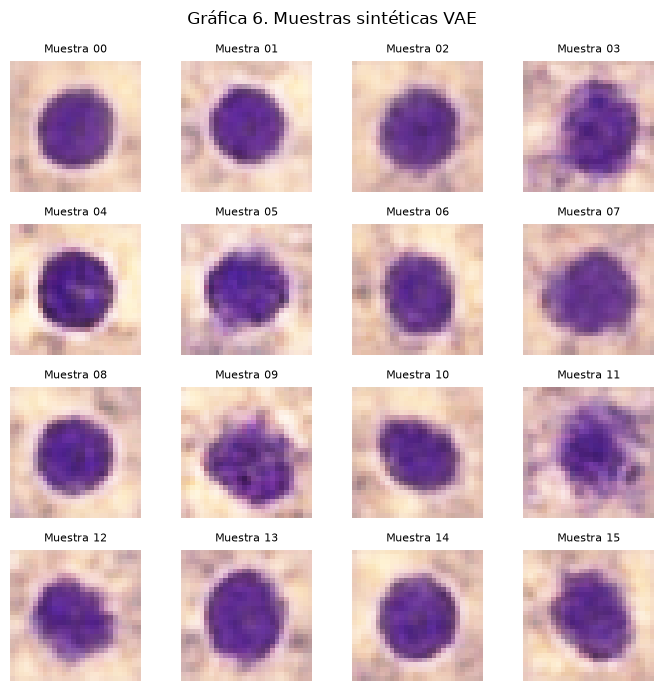

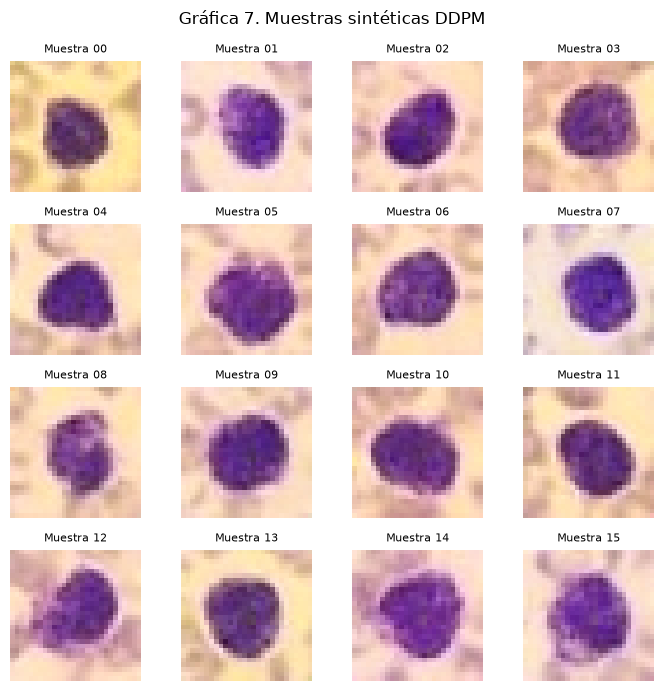

Carga de checkpoints sin reentrenar y generación reutilizable de 2 imágenes por modelo: verificados.
Generación VAE: 300 imágenes en 0.02s (muestreo; GPU).
Generación DDPM: 300 imágenes, 50 pasos de inferencia, en 12.49s (muestreo; GPU).


,Modelo,Épocas,Pérdida final,Tiempo entrenamiento (s),Actualizaciones
0,CNN referencia,10,0.472257,NaN,NaN
1,VAE,300,49.780727,13.072183,NaN
2,DDPM,300,0.030810,112.036502,2100.0


Auditoría escrita: /home/juanes/Tareas/9 Semestre/Analisis Deep learning/Talleres/Taller 4/artefactos/persona2/auditoria/entrega_persona1_recalculada.md
Índices seleccionados: /home/juanes/Tareas/9 Semestre/Analisis Deep learning/Talleres/Taller 4/artefactos/persona1/idx_sub.npy; configuración: /home/juanes/Tareas/9 Semestre/Analisis Deep learning/Talleres/Taller 4/artefactos/persona1/configuracion.json


In [5]:
def sincronizar_si_cuda(device=DISPOSITIVO):
    if device.type == "cuda":
        torch.cuda.synchronize(device)

def generar_vae(modelo, cantidad, batch_size=64, seed=123, device=DISPOSITIVO):
    modelo = modelo.to(device).eval()
    generador = torch.Generator(device=device).manual_seed(seed)
    lotes = []
    for inicio in range(0, cantidad, batch_size):
        n_lote = min(batch_size, cantidad - inicio)
        z = torch.randn(n_lote, modelo.latent_dim, generator=generador, device=device)
        with torch.no_grad():
            lotes.append(modelo.decode(z).cpu())
    return torch.cat(lotes) if lotes else torch.empty((0, 3, 28, 28))

def generar_ddpm(modelo, cantidad, pasos_inferencia=50, batch_size=16, seed=456, device=DISPOSITIVO, scheduler=None):
    modelo = modelo.to(device).eval()
    scheduler = copy.deepcopy(scheduler) if scheduler is not None else DDPMScheduler.from_pretrained(DDPM_DIR / "scheduler")
    scheduler.set_timesteps(pasos_inferencia, device=device)
    generador = torch.Generator(device=device).manual_seed(seed)
    lotes = []
    for inicio in range(0, cantidad, batch_size):
        n_lote = min(batch_size, cantidad - inicio)
        x = torch.randn((n_lote, 3, 28, 28), generator=generador, device=device)
        with torch.no_grad():
            for timestep in scheduler.timesteps:
                prediccion = modelo(x, timestep).sample
                x = scheduler.step(prediccion, timestep, x, generator=generador).prev_sample
        lotes.append(x.clamp(-1, 1).cpu())
    return torch.cat(lotes) if lotes else torch.empty((0, 3, 28, 28))

def guardar_png_rgb(tensores, carpeta):
    carpeta = Path(carpeta)
    carpeta.mkdir(parents=True, exist_ok=True)
    datos = ((tensores.detach().cpu().clamp(-1, 1) + 1) * 127.5).round().byte().permute(0, 2, 3, 1).numpy()
    for indice, imagen in enumerate(datos):
        Image.fromarray(imagen).save(carpeta / f"{indice:03d}.png", format="PNG")

def mostrar_cuadricula(tensores, titulo, nombre_archivo):
    cantidad = min(16, len(tensores))
    fig, axes = plt.subplots(4, 4, figsize=(7, 7))
    for indice, ax in enumerate(axes.flat):
        if indice < cantidad:
            imagen = ((tensores[indice].clamp(-1, 1) + 1) / 2).permute(1, 2, 0).numpy()
            ax.imshow(imagen)
            ax.set_title(f"Muestra {indice:02d}", fontsize=8)
        ax.axis("off")
    fig.suptitle(titulo)
    fig.tight_layout()
    fig.savefig(GRAFICAS / nombre_archivo, dpi=150, bbox_inches="tight")
    plt.show()

def cargar_png_como_tensor(carpeta):
    archivos = sorted(Path(carpeta).glob("*.png"))
    assert len(archivos) == 300
    datos = np.stack([np.asarray(Image.open(ruta).convert("RGB"), dtype=np.uint8) for ruta in archivos])
    return torch.as_tensor(datos).permute(0, 3, 1, 2).div(127.5).sub(1.0)

modelo_vae, vae_checkpoint = cargar_vae()
modelo_ddpm, scheduler_ddpm, ddpm_checkpoint = cargar_ddpm()
configuracion_heredada = json.loads((ARTEFACTOS / "configuracion.json").read_text(encoding="utf-8"))
PASOS_INFERENCIA_DDPM = 50
if len(sorted((ARTEFACTOS / "vae_imagenes").glob("*.png"))) == 300:
    imagenes_vae = cargar_png_como_tensor(ARTEFACTOS / "vae_imagenes")
    tiempo_generacion_vae = float(configuracion_heredada["vae"]["tiempo_generacion_300_segundos"])
    print("VAE: se reutilizan los 300 PNG heredados; no se sobrescribe persona1.")
else:
    if DISPOSITIVO.type == "cuda":
        sincronizar_si_cuda()
    inicio = time.perf_counter()
    imagenes_vae = generar_vae(modelo_vae, 300, batch_size=64, seed=1001)
    sincronizar_si_cuda()
    tiempo_generacion_vae = time.perf_counter() - inicio
    guardar_png_rgb(imagenes_vae, RAIZ_AUDITORIA / "vae_imagenes")

if len(sorted((ARTEFACTOS / "ddpm_imagenes").glob("*.png"))) == 300:
    imagenes_ddpm = cargar_png_como_tensor(ARTEFACTOS / "ddpm_imagenes")
    tiempo_generacion_ddpm = float(configuracion_heredada["ddpm"]["tiempo_generacion_300_segundos"])
    print("DDPM: se reutilizan los 300 PNG heredados; no se sobrescribe persona1.")
else:
    if DISPOSITIVO.type == "cuda":
        sincronizar_si_cuda()
    inicio = time.perf_counter()
    imagenes_ddpm = generar_ddpm(modelo_ddpm, 300, pasos_inferencia=PASOS_INFERENCIA_DDPM, batch_size=16, seed=1002, scheduler=scheduler_ddpm)
    sincronizar_si_cuda()
    tiempo_generacion_ddpm = time.perf_counter() - inicio
    guardar_png_rgb(imagenes_ddpm, RAIZ_AUDITORIA / "ddpm_imagenes")

for nombre, carpeta in (("VAE", ARTEFACTOS / "vae_imagenes"), ("DDPM", ARTEFACTOS / "ddpm_imagenes")):
    archivos = sorted(carpeta.glob("*.png"))
    assert len(archivos) == 300, f"{nombre}: se esperaban 300 PNG y hay {len(archivos)}"
    assert archivos[0].name == "000.png" and archivos[-1].name == "299.png"
    for ruta in archivos:
        with Image.open(ruta) as imagen:
            assert imagen.size == (28, 28) and imagen.mode == "RGB", f"Archivo no RGB 28x28: {ruta}"
    print(f"{nombre}: {len(archivos)} PNG RGB 28x28 verificados en {carpeta}")

mostrar_cuadricula(imagenes_vae, "Gráfica 6. Muestras sintéticas VAE", "muestras_vae.png")
mostrar_cuadricula(imagenes_ddpm, "Gráfica 7. Muestras sintéticas DDPM", "muestras_ddpm.png")
assert len(generar_vae(modelo_vae, 2, seed=2001)) == 2
assert len(generar_ddpm(modelo_ddpm, 2, pasos_inferencia=PASOS_INFERENCIA_DDPM, seed=2002, scheduler=scheduler_ddpm)) == 2
print("Carga de checkpoints sin reentrenar y generación reutilizable de 2 imágenes por modelo: verificados.")
print(f"Generación VAE: 300 imágenes en {tiempo_generacion_vae:.2f}s (muestreo; {'GPU' if DISPOSITIVO.type == 'cuda' else 'CPU'}).")
print(f"Generación DDPM: 300 imágenes, {PASOS_INFERENCIA_DDPM} pasos de inferencia, en {tiempo_generacion_ddpm:.2f}s (muestreo; {'GPU' if DISPOSITIVO.type == 'cuda' else 'CPU'}).")

configuracion_final = {
    "semilla": SEMILLA, "N": int(N), "idx_sub": "idx_sub.npy",
    "clases": NOMBRES_CLASES, "forma_rgb": [28, 28, 3], "rango_imagen_original": [0, 255],
    "cnn": {**cnn_config, "metricas_test": metricas_cnn, "historial": cnn_historial, "checkpoint": str(CNN_PATH.relative_to(RAIZ))},
    "vae": {**vae_config, "epocas_realizadas": epocas_vae, "historial_final": {k: v[-1] for k, v in vae_historial.items()}, "tiempo_entrenamiento_segundos": vae_segundos, "checkpoint": str(VAE_PATH.relative_to(RAIZ)), "imagenes": "artefactos/persona1/vae_imagenes/000.png..299.png", "tiempo_generacion_300_segundos": tiempo_generacion_vae},
    "ddpm": {**ddpm_config, "epocas_completas": ddpm_epocas, "epoca_parcial": ddpm_parcial, "perdida_final": ddpm_historial[-1], "historial": ddpm_historial, "actualizaciones_reales": ddpm_actualizaciones, "tiempo_entrenamiento_segundos": ddpm_segundos, "pasos_inferencia": PASOS_INFERENCIA_DDPM, "checkpoint": "artefactos/persona1/ddpm/", "imagenes": "artefactos/persona1/ddpm_imagenes/000.png..299.png", "tiempo_generacion_300_segundos": tiempo_generacion_ddpm},
    "particiones": {k: "MedMNIST BloodMNIST split oficial" for k in particiones},
    "dispositivo": str(DISPOSITIVO), "python": __import__("sys").version.split()[0],
    "versiones": {"torch": torch.__version__, "medmnist": __import__("medmnist").__version__, "diffusers": __import__("diffusers").__version__},
}
with open(RAIZ_AUDITORIA / "configuracion_recalculada.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion_final, archivo, ensure_ascii=False, indent=2)

tabla_resumen = pd.DataFrame([
    {"Modelo": "CNN referencia", "Épocas": epocas_cnn, "Pérdida final": cnn_historial["val_loss"][-1], "Tiempo entrenamiento (s)": None, "Actualizaciones": None},
    {"Modelo": "VAE", "Épocas": epocas_vae, "Pérdida final": vae_historial["total"][-1], "Tiempo entrenamiento (s)": vae_segundos, "Actualizaciones": None},
    {"Modelo": "DDPM", "Épocas": ddpm_epocas, "Pérdida final": ddpm_historial[-1], "Tiempo entrenamiento (s)": ddpm_segundos, "Actualizaciones": ddpm_actualizaciones},
])
display(tabla_resumen)

lineas_entrega = [
    "# Entrega persona 1 — Taller 4", "",
    "## Estado", "",
    "Completadas: actividad 1 (exploración y CNN de referencia), actividad 2.1 (VAE), actividad 2.2 (DDPM) y actividad 2.3 (300 PNG por generador). Las actividades 3, 4, 5 y el bono GAN quedan explícitamente para la persona 2.", "",
    f"Dispositivo de ejecución: {DISPOSITIVO}" + (f" ({torch.cuda.get_device_name(0)})" if DISPOSITIVO.type == "cuda" else " (sin GPU utilizable; los límites de GPU no se consumieron)."),
    f"Python {__import__('sys').version.split()[0]}; PyTorch {torch.__version__}; MedMNIST {__import__('medmnist').__version__}; diffusers {__import__('diffusers').__version__}.", "",
    "## Datos y CNN de referencia", "",
    f"BloodMNIST oficial: N={N} basófilos en train; índices únicos seleccionados con `default_rng(42)`: 200. Conteos train: `{conteos.loc['train'].to_dict()}`; val: `{conteos.loc['val'].to_dict()}`; test: `{conteos.loc['test'].to_dict()}`.",
    f"CNN: {epocas_cnn} épocas, mejor val_loss={metricas_cnn['mejor_val_loss']:.6f}; test F1 macro={metricas_cnn['f1_macro']:.6f}, F1 basófilo={metricas_cnn['f1_basofilo']:.6f}, recall basófilo={metricas_cnn['recall_basofilo']:.6f}.",
    "Entrada CNN RGB en [0,1]. Checkpoint: `artefactos/persona1/cnn_referencia.pt`; métricas, `y_true`, `y_pred` e historial: `artefactos/persona1/metricas_cnn.json`.",
    "El archivo `idx_sub.npy` contiene las posiciones dentro de `train`; los 200 basófilos originales se reconstruyen con `train.imgs[np.load(ARTEFACTOS / 'idx_sub.npy')]`. Recuperar N: `int((train.labels.ravel() == 0).sum())`. La persona 2 puede reusar `CNNReferencia` del notebook y cargar `state_dict` del checkpoint; sus datos sintéticos deben convertirse con el mismo `imagenes_a_tensor(..., 'cero_uno')`.", "",
    "## Generadores", "",
    f"VAE: latent_dim=16, Adam lr=1e-3, batch=32, {epocas_vae} épocas; pérdidas finales total={vae_historial['total'][-1]:.6f}, reconstrucción={vae_historial['reconstruccion'][-1]:.6f}, KL={vae_historial['kl'][-1]:.6f}; entrenamiento {vae_segundos:.2f}s ({'GPU' if DISPOSITIVO.type == 'cuda' else 'CPU'}). Checkpoint: `artefactos/persona1/vae.pt`.",
    f"DDPM: UNet2DModel canales {ddpm_config['block_out_channels']}, DDPMScheduler train=1000, AdamW lr=1e-4, batch=32; {ddpm_epocas} épocas completas, parcial={ddpm_parcial}, {ddpm_actualizaciones} actualizaciones; MSE final={ddpm_historial[-1]:.6f}; entrenamiento {ddpm_segundos:.2f}s ({'GPU' if DISPOSITIVO.type == 'cuda' else 'CPU'}). Checkpoint y configuración: `artefactos/persona1/ddpm/`.",
    f"Los generadores reciben RGB `[0,255] -> [-1,1]`; al guardar se mapea a PNG RGB `[0,255]`. VAE 300 imágenes: `artefactos/persona1/vae_imagenes/`; DDPM 300 imágenes: `artefactos/persona1/ddpm_imagenes/`, inferencia={PASOS_INFERENCIA_DDPM} pasos. Tiempo de muestreo de 300: VAE {tiempo_generacion_vae:.2f}s; DDPM {tiempo_generacion_ddpm:.2f}s.",
    "Funciones para generar cantidades arbitrarias: `generar_vae(modelo, cantidad, ...)` y `generar_ddpm(modelo, cantidad, pasos_inferencia=50, scheduler=scheduler_ddpm)`. Carga VAE: `modelo_vae, vae_checkpoint = cargar_vae()`. Carga DDPM sin reentrenar: `modelo_ddpm, scheduler_ddpm, metadata = cargar_ddpm()`. Carga CNN: `modelo_cnn, checkpoint = cargar_cnn_referencia()`.", "",
    "## Continuación de la persona 2", "",
    "Al reabrir el notebook, ejecutar hasta las celdas que definen las clases y funciones de carga; el código detecta checkpoints y no vuelve a entrenar. Para la actividad 3, inspeccionar 16 muestras y comparar las 300 imágenes con test usando los procedimientos del enunciado. Para la actividad 4, `N-200` imágenes sintéticas se pueden pedir al generador elegido mediante `generar_vae` o `generar_ddpm`; reconstruir las imágenes de train y test desde `BloodMNIST(split=..., download=True)`, conservar particiones oficiales y evaluar las tres CNN. La persona 2 debe ejecutar por separado las actividades 3, 4 y 5: aquí no se calcularon distancias/diversidad/memorización, no se eligió generador ni se entrenaron las dos CNN comparativas.", "",
    "## Reproducción, fuentes y limitaciones", "",
    "Entorno usado: Python 3.13.2 y el `.venv` del repositorio. Activar en PowerShell: `.venv\\Scripts\\Activate.ps1`. Instalar PyTorch para CUDA desde la instrucción oficial compatible con el driver/GPU y después `python -m pip install diffusers medmnist numpy pandas matplotlib scikit-learn pillow ipykernel jupyter nbformat nbconvert`. Abrir `Taller 4/juan_alvarez_daniel_ortiz.ipynb` en VS Code, seleccionar `.venv` como kernel y ejecutar de arriba abajo. MedMNIST descarga BloodMNIST a su caché de usuario; no se copia el dataset al repositorio.",
    "MedMNIST informa que BloodMNIST está bajo CC BY 4.0 (dataset); citar Yang et al., *MedMNIST v2: A Large-Scale Lightweight Benchmark for 2D and 3D Biomedical Image Classification*, Scientific Data 10, 41 (2023), doi:10.1038/s41597-022-01721-8, y también Yang, Shi & Ni, ISBI 2021, doi:10.1109/ISBI48211.2021.9434062. La licencia del código MedMNIST es Apache-2.0 y es distinta de la licencia de los datos. DDPM se implementó con Hugging Face Diffusers; citar Ho et al., *Denoising Diffusion Probabilistic Models* (NeurIPS 2020) y la documentación de diffusers. BloodMNIST y estos resultados son académicos; no son para uso clínico.",
    "Fuentes oficiales: https://medmnist.com/ ; https://github.com/MedMNIST/MedMNIST ; https://doi.org/10.5281/zenodo.10519652 ; https://huggingface.co/docs/diffusers/ ; https://arxiv.org/abs/2006.11239 .", "",
    "## Visual inspection", "",
    "The grids of 48 real images and synthetic samples are saved in `artefactos/persona1/graficas/`. Both generators produced cell-like purple central regions; the VAE samples look smoother, while the DDPM samples show somewhat more variation but remain low-resolution with soft edges and limited detail. This is a visual check only, not the formal evaluation in activity 3.",
    ]
(RAIZ_AUDITORIA / "entrega_persona1_recalculada.md").write_text("\n".join(lineas_entrega) + "\n", encoding="utf-8")
print(f"Auditoría escrita: {RAIZ_AUDITORIA / 'entrega_persona1_recalculada.md'}")
print(f"Índices seleccionados: {ARTEFACTOS / 'idx_sub.npy'}; configuración: {ARTEFACTOS / 'configuracion.json'}")


### Resultados observados y limitaciones

La CNN de referencia obtuvo en el test oficial F1 macro **0.769993**, F1 de bas?filo **0.331081** y recall de bas?filo **0.200820**. El desempe?o por clase es desigual: el F1 macro resume las ocho clases, mientras que las m?tricas de bas?filo son m?s bajas con solo 200 ejemplos de esa clase en entrenamiento. Estos son resultados de una ?nica semilla, no una comparaci?n de los generadores ni evidencia cl?nica.

El VAE complet? 300 ?pocas en **13.07 s de GPU**; sus p?rdidas finales por imagen fueron total **49.7807**, reconstrucci?n **28.0898** y KL **21.6909**. El DDPM complet? 300 ?pocas y **2,100 actualizaciones reales** en **112.04 s de GPU**, con MSE final **0.030810**. Sus 1,000 pasos describen el scheduler de entrenamiento; para las 300 im?genes se usaron **50 pasos de inferencia**. Los tiempos separados de generaci?n fueron **0.02 s** para el VAE y **12.49 s** para DDPM.

En las cuadr?culas de muestra, ambos modelos producen regiones centrales viol?ceas con aspecto celular, pero los bordes y detalles finos son suaves y poco definidos a 28?28. En estas 16 muestras el VAE se ve m?s suavizado; DDPM presenta algo m?s de variaci?n de forma y textura, aunque tambi?n mantiene contornos suaves. Esta observaci?n es descriptiva y no sustituye la comparaci?n formal de calidad, diversidad o memorizaci?n, reservada a la persona 2.

### Referencias académicas y licencia

BloodMNIST/MedMNIST se distribuye bajo **CC BY 4.0** (la licencia Apache-2.0 del repositorio corresponde al código, no a las imágenes). Citar: Yang, J. et al. (2023), “MedMNIST v2: A Large-Scale Lightweight Benchmark for 2D and 3D Biomedical Image Classification”, *Scientific Data*, 10, 41. https://doi.org/10.1038/s41597-022-01721-8; y Yang, J., Shi, R. & Ni, B. (2021), “MedMNIST Classification Decathlon: A Lightweight AutoML Benchmark for Medical Image Analysis”, ISBI. https://doi.org/10.1109/ISBI48211.2021.9434062. Dataset oficial y licencia: https://doi.org/10.5281/zenodo.10519652.

La implementación del DDPM usa Hugging Face `diffusers` y sus clases `UNet2DModel` y `DDPMScheduler` (https://huggingface.co/docs/diffusers/); referencia del proceso: Ho, J., Jain, A. & Abbeel, P. (2020), “Denoising Diffusion Probabilistic Models”, NeurIPS. https://arxiv.org/abs/2006.11239. Estas evaluaciones son académicas; BloodMNIST no está destinado al uso clínico.

## P0. Verificación del punto de partida (persona 2)

Se validan los hechos heredados sin reentrenar: 200 índices relativos a `train`, `N=852`, tres checkpoints cargables, 300 PNG RGB 28×28 por generador base y métricas de referencia recalculadas desde `metricas_cnn.json`. Las imágenes y los checkpoints de persona 1 solo se leen.

In [6]:
metricas_ref_json = json.loads((ARTEFACTOS / "metricas_cnn.json").read_text(encoding="utf-8"))
config_ref_json = json.loads((ARTEFACTOS / "configuracion.json").read_text(encoding="utf-8"))
metricas_ref = metricas_ref_json["metricas"]
idx_guardados = np.load(ARTEFACTOS / "idx_sub.npy")
assert len(idx_guardados) == 200 and len(np.unique(idx_guardados)) == 200
assert np.array_equal(idx_guardados, idx_sub)
assert int((train.labels.ravel() == 0).sum()) == N == 852
assert np.all(train.labels.ravel()[idx_sub] == 0)
assert abs(metricas_ref["f1_macro"] - config_ref_json["cnn"]["metricas_test"]["f1_macro"]) < 1e-12
assert abs(metricas_ref["f1_basofilo"] - config_ref_json["cnn"]["metricas_test"]["f1_basofilo"]) < 1e-12
assert abs(metricas_ref["recall_basofilo"] - config_ref_json["cnn"]["metricas_test"]["recall_basofilo"]) < 1e-12
rec_ref = float(f1_score(metricas_ref_json["y_true"], metricas_ref_json["y_pred"], average="macro", zero_division=0))
assert abs(rec_ref - metricas_ref["f1_macro"]) < 1e-12
rec_baso = float(f1_score(np.asarray(metricas_ref_json["y_true"]) == 0, np.asarray(metricas_ref_json["y_pred"]) == 0, zero_division=0))
rr_baso = float(recall_score(np.asarray(metricas_ref_json["y_true"]) == 0, np.asarray(metricas_ref_json["y_pred"]) == 0, zero_division=0))
assert abs(rec_baso - metricas_ref["f1_basofilo"]) < 1e-12
assert abs(rr_baso - metricas_ref["recall_basofilo"]) < 1e-12
checkpoint_cnn_p0 = torch.load(CNN_PATH, map_location="cpu", weights_only=True)
checkpoint_vae_p0 = torch.load(VAE_PATH, map_location="cpu", weights_only=True)
checkpoint_ddpm_p0 = torch.load(DDPM_DIR / "training_metadata.pt", map_location="cpu", weights_only=True)
assert len(checkpoint_cnn_p0["state_dict"]) == 8 and len(checkpoint_vae_p0["state_dict"]) == 16
for nombre_carpeta in ("vae_imagenes", "ddpm_imagenes"):
    archivos_p0 = sorted((ARTEFACTOS / nombre_carpeta).glob("*.png"))
    assert len(archivos_p0) == 300 and archivos_p0[0].name == "000.png" and archivos_p0[-1].name == "299.png"
    for ruta_p0 in archivos_p0:
        with Image.open(ruta_p0) as img_p0:
            assert img_p0.size == (28, 28) and img_p0.mode == "RGB"
tabla_p0 = pd.DataFrame([
    {"Verificación": "idx_sub", "Valor": "200 únicos, etiqueta 0, coincide con archivo"},
    {"Verificación": "N", "Valor": f"{N} basófilos en train"},
    {"Verificación": "Checkpoints", "Valor": "CNN, VAE y DDPM cargados con weights_only=True"},
    {"Verificación": "PNG base", "Valor": "300 VAE + 300 DDPM, RGB 28x28"},
    {"Verificación": "Métricas CNN", "Valor": f"F1 macro={metricas_ref['f1_macro']:.12f}; F1 basófilo={metricas_ref['f1_basofilo']:.12f}; recall={metricas_ref['recall_basofilo']:.12f}"},
])
display(tabla_p0)
print("P0 verificado; artefactos de persona 1 permanecen sin cambios.")

,Verificación,Valor
0,idx_sub,"200 únicos, etiqueta 0, coincide con archivo"
1,N,852 basófilos en train
2,Checkpoints,"CNN, VAE y DDPM cargados con weights_only=True"
3,PNG base,"300 VAE + 300 DDPM, RGB 28x28"
4,Métricas CNN,F1 macro=0.769992617164; F1 basófilo=0.3310810...


P0 verificado; artefactos de persona 1 permanecen sin cambios.


## Actividad 3. Evaluación de las imágenes generadas

Se usa el protocolo común para VAE y DDPM y, después, para la GAN del bono. Las reglas de muestreo, documentadas en los JSON, son: primeras 100 PNG para distancias, primeros 100 basófilos de `test` en orden oficial, 300 sintéticas para clasificación y vecinos, y los 244 basófilos de `test` frente a los mismos 200 basófilos de `train` para la comparación de memorización. Todas las distancias se calculan en `[0,1]` sobre vectores aplanados de 2.352 componentes.

In [7]:
RUTA_EVALUACION = ARTEFACTOS_P2 / "evaluacion"
RUTA_MODELOS = ARTEFACTOS_P2 / "modelos"
RUTA_GRAFICAS = ARTEFACTOS_P2 / "graficas"
RUTA_GAN_IMG = ARTEFACTOS_P2 / "gan_imagenes"
RUTA_GAN_MODELOS = RUTA_MODELOS / "gan"
for carpeta_p2 in (ARTEFACTOS_P2, RUTA_EVALUACION, RUTA_MODELOS, RUTA_GRAFICAS, RUTA_GAN_IMG, RUTA_GAN_MODELOS):
    carpeta_p2.mkdir(parents=True, exist_ok=True)
RECALL_REFERENCIA = float(metricas_ref["recall_basofilo"])
IDX_BASO_TEST = np.flatnonzero(test.labels.ravel() == 0)
assert len(IDX_BASO_TEST) == 244
basofilos_test_uint8 = test.imgs[IDX_BASO_TEST]
basofilos_train_uint8 = basofilos_train

def cargar_png_rgb(carpeta, cantidad=300):
    archivos = sorted(Path(carpeta).glob("*.png"))
    assert len(archivos) == cantidad, f"Se esperaban {cantidad} PNG en {carpeta} y hay {len(archivos)}"
    datos = np.stack([np.asarray(Image.open(ruta).convert("RGB"), dtype=np.uint8) for ruta in archivos])
    assert datos.shape == (cantidad, 28, 28, 3) and datos.dtype == np.uint8
    return datos

def imagenes_a_float01(imagenes_uint8):
    return np.asarray(imagenes_uint8, dtype=np.float32) / 255.0

def predecir_cnn(modelo, imagenes_uint8, batch_size=256):
    modelo.eval()
    predicciones = []
    with torch.no_grad():
        for inicio in range(0, len(imagenes_uint8), batch_size):
            lote = imagenes_a_tensor(imagenes_uint8[inicio:inicio + batch_size], "cero_uno").to(DISPOSITIVO)
            predicciones.append(modelo(lote).argmax(dim=1).cpu().numpy())
    return np.concatenate(predicciones).astype(np.int64)

def distancias_pares(x, y=None):
    a = torch.as_tensor(np.asarray(x, dtype=np.float32).reshape(len(x), -1))
    if y is None:
        distancia = torch.cdist(a, a)
        triangulo = torch.triu_indices(len(a), len(a), offset=1)
        return float(distancia[triangulo[0], triangulo[1]].mean().item())
    b = torch.as_tensor(np.asarray(y, dtype=np.float32).reshape(len(y), -1))
    return float(torch.cdist(a, b).mean().item())

def matriz_distancias(consultas, referencia):
    q = torch.as_tensor(np.asarray(consultas, dtype=np.float32).reshape(len(consultas), -1))
    r = torch.as_tensor(np.asarray(referencia, dtype=np.float32).reshape(len(referencia), -1))
    return torch.cdist(q, r).numpy()

def resumen_distancias(valores):
    valores = np.asarray(valores, dtype=np.float64)
    assert np.all(np.isfinite(valores)) and np.all(valores >= 0)
    return {"media": float(valores.mean()), "mediana": float(np.median(valores)), "min": float(valores.min()), "p10": float(np.percentile(valores, 10)), "p90": float(np.percentile(valores, 90))}

def vecinos_cercanos(consultas, referencia, n_top=5):
    distancia = matriz_distancias(consultas, referencia)
    indices = distancia.argmin(axis=1).astype(np.int64)
    minimas = distancia[np.arange(len(distancia)), indices]
    pares = []
    for plano in np.argsort(distancia.ravel())[:n_top]:
        fila, columna = np.unravel_index(plano, distancia.shape)
        pares.append({"indice_consulta": int(fila), "indice_referencia": int(columna), "distancia": float(distancia[fila, columna])})
    assert [par["distancia"] for par in pares] == sorted(par["distancia"] for par in pares)
    assert all(0 <= par["indice_referencia"] <= 199 for par in pares)
    return minimas, indices, pares

def graficar_vecinos(nombre, consultas_uint8, referencia_uint8, pares):
    figura, ejes = plt.subplots(5, 2, figsize=(5.5, 12))
    for fila, par in enumerate(pares):
        ejes[fila, 0].imshow(consultas_uint8[par["indice_consulta"]])
        ejes[fila, 1].imshow(referencia_uint8[par["indice_referencia"]])
        ejes[fila, 0].set_title(f"{nombre} {par['indice_consulta']}", fontsize=8)
        ejes[fila, 1].set_title(f"train {par['indice_referencia']} d={par['distancia']:.3f}", fontsize=8)
        ejes[fila, 0].axis("off")
        ejes[fila, 1].axis("off")
    figura.suptitle(f"Cinco pares más similares — {nombre}")
    figura.tight_layout()
    figura.savefig(RUTA_GRAFICAS / f"vecinos_{nombre.lower()}_top5.png", dpi=150, bbox_inches="tight")
    plt.show()

def evaluar_generador(nombre, imagenes_uint8, tiempo_generacion_s, pasos_inferencia, origen_tiempo, hacer_grafico=True):
    predicciones = predecir_cnn(modelo_cnn, imagenes_uint8)
    conteo = Counter(predicciones.tolist())
    fraccion_basofilo = float((predicciones == 0).mean())
    sinteticas_100 = imagenes_a_float01(imagenes_uint8[:100])
    reales_100 = imagenes_a_float01(basofilos_test_uint8[:100])
    diversidad = {
        "media_sintetica": distancias_pares(sinteticas_100),
        "media_real": distancias_pares(reales_100),
        "media_cruzada": distancias_pares(sinteticas_100, reales_100),
    }
    min_sint, idx_sint, pares = vecinos_cercanos(imagenes_a_float01(imagenes_uint8), imagenes_a_float01(basofilos_train_uint8))
    min_test, idx_test, _ = vecinos_cercanos(imagenes_a_float01(basofilos_test_uint8), imagenes_a_float01(basofilos_train_uint8))
    if hacer_grafico:
        graficar_vecinos(nombre, imagenes_uint8, basofilos_train_uint8, pares)
    return {
        "clasificacion": {
            "n": int(len(imagenes_uint8)),
            "fraccion_basofilo": fraccion_basofilo,
            "recall_referencia_test": RECALL_REFERENCIA,
            "conteo_predicciones": {NOMBRES_CLASES[i]: int(conteo.get(i, 0)) for i in range(8)},
            "conteo_por_indice": {str(i): int(conteo.get(i, 0)) for i in range(8)},
        },
        "diversidad": diversidad,
        "memorizacion": {
            "sinteticas": resumen_distancias(min_sint),
            "test": resumen_distancias(min_test),
            "top5": pares,
            "vecino_train_sinteticas": idx_sint.tolist(),
            "vecino_train_test": idx_test.tolist(),
        },
        "costo": {"tiempo_generacion_300_s": float(tiempo_generacion_s), "pasos_inferencia": pasos_inferencia, "dispositivo": str(DISPOSITIVO), "origen_tiempo": origen_tiempo},
    }

def cuadricula_uint8(imagenes_uint8, titulo, nombre_archivo):
    figura, ejes = plt.subplots(4, 4, figsize=(7, 7))
    for indice, eje in enumerate(ejes.flat):
        if indice < 16:
            eje.imshow(imagenes_uint8[indice])
            eje.set_title(f"Muestra {indice:02d}", fontsize=8)
        eje.axis("off")
    figura.suptitle(titulo)
    figura.tight_layout()
    figura.savefig(RUTA_GRAFICAS / nombre_archivo, dpi=150, bbox_inches="tight")
    plt.show()

print("Funciones de evaluación definidas; basófilos de test =", len(IDX_BASO_TEST))

Funciones de evaluación definidas; basófilos de test = 244


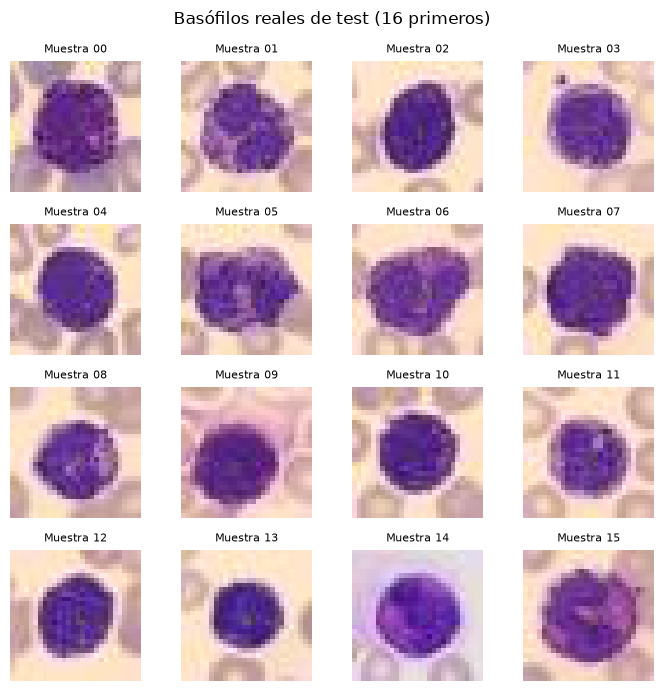

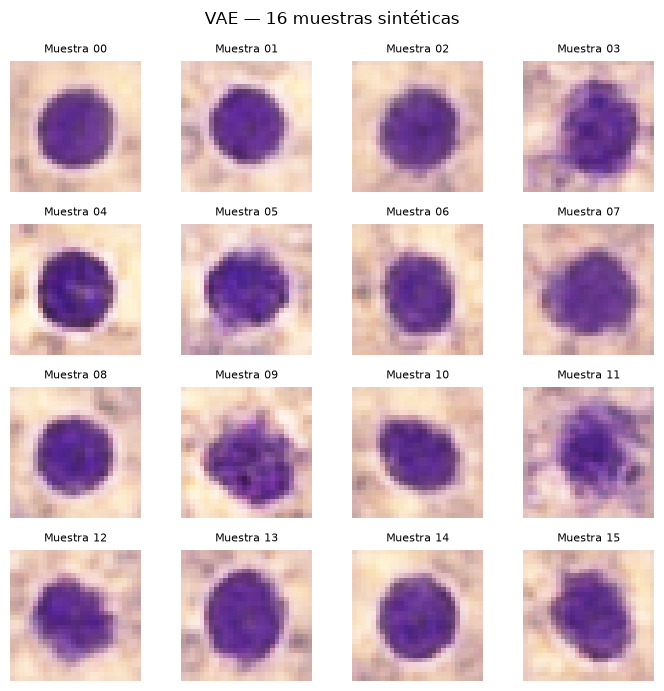

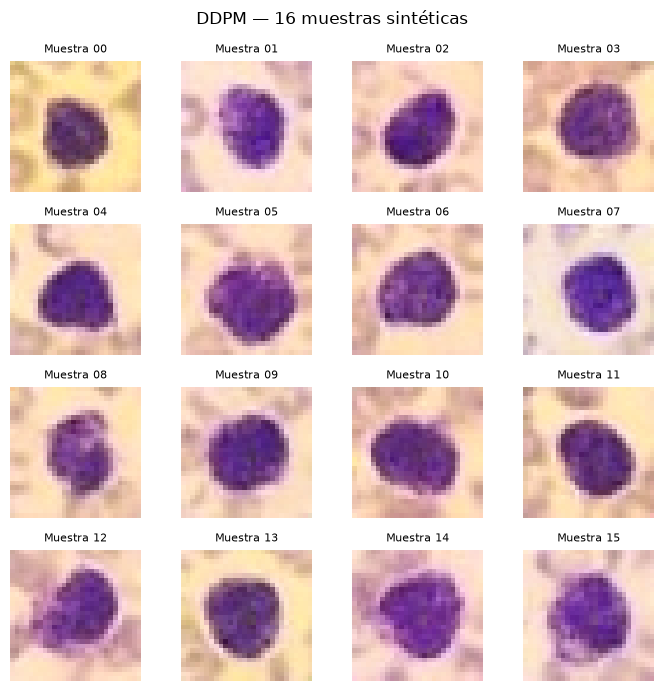

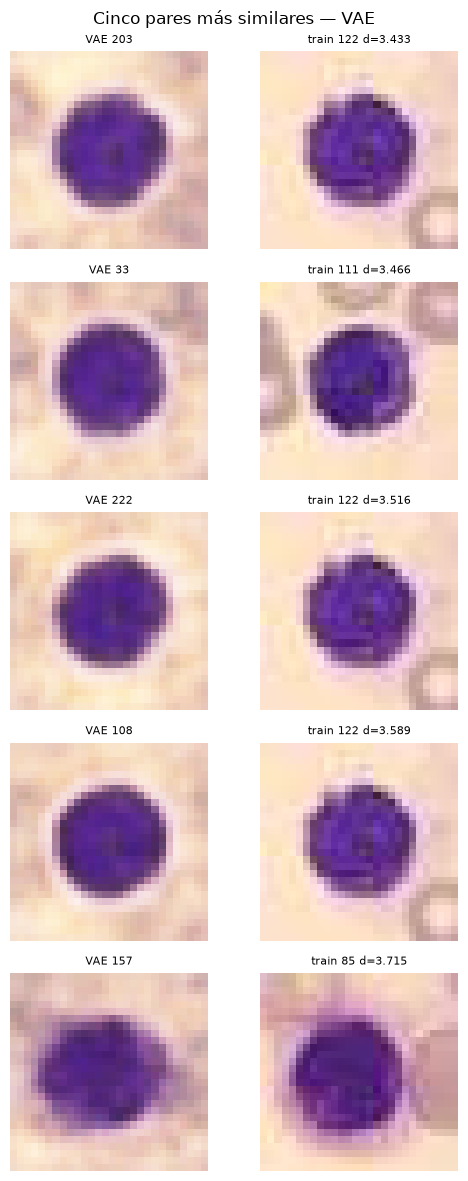

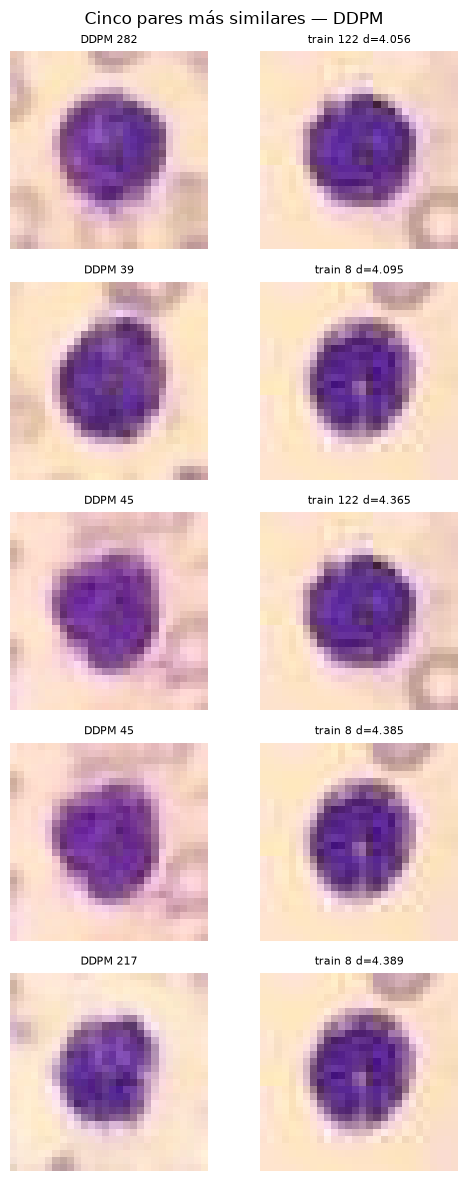

,Fracción basófilo,Diversidad sintética,Diversidad real,Distancia cruzada,NN sintética media,NN test media,Tiempo 300 (s)
Generador,,,,,,,
VAE,0.03,6.4951,8.1936,7.4307,4.8824,5.7661,0.0234
DDPM,0.03,7.5209,8.1936,8.4574,5.9766,5.7661,12.4873


Recall de referencia usado como comparación: 0.200819672131


In [8]:
imagenes_vae_uint8 = cargar_png_rgb(ARTEFACTOS / "vae_imagenes")
imagenes_ddpm_uint8 = cargar_png_rgb(ARTEFACTOS / "ddpm_imagenes")
cuadricula_uint8(basofilos_test_uint8[:16], "Basófilos reales de test (16 primeros)", "muestras_test_basofilos.png")
cuadricula_uint8(imagenes_vae_uint8[:16], "VAE — 16 muestras sintéticas", "muestras_vae_eval.png")
cuadricula_uint8(imagenes_ddpm_uint8[:16], "DDPM — 16 muestras sintéticas", "muestras_ddpm_eval.png")

metricas_generadores = {
    "muestreo": {"n_visuales": 16, "n_distancia": 100, "regla": "primeras 100 PNG y primeros 100 basófilos de test en orden oficial"},
    "referencia": {"recall_basofilo_test": RECALL_REFERENCIA, "fuente": "artefactos/persona1/metricas_cnn.json"},
    "modelos": {},
}
predicciones_sinteticas = {"referencia": {"recall_basofilo_test": RECALL_REFERENCIA}, "modelos": {}}
config_heredada = json.loads((ARTEFACTOS / "configuracion.json").read_text(encoding="utf-8"))
entradas_evaluacion = [
    ("VAE", imagenes_vae_uint8, config_heredada["vae"]["tiempo_generacion_300_segundos"], None, "heredado de persona1/configuracion.json"),
    ("DDPM", imagenes_ddpm_uint8, config_heredada["ddpm"]["tiempo_generacion_300_segundos"], PASOS_INFERENCIA_DDPM, "heredado de persona1/configuracion.json"),
]
for nombre, imagenes, tiempo, pasos, origen in entradas_evaluacion:
    metricas_generadores["modelos"][nombre] = evaluar_generador(nombre, imagenes, tiempo, pasos, origen)
    predicciones_sinteticas["modelos"][nombre] = {
        "predicciones": predecir_cnn(modelo_cnn, imagenes).tolist(),
        "n": 300,
    }

with open(RUTA_EVALUACION / "metricas_generadores.json", "w", encoding="utf-8") as archivo:
    json.dump(metricas_generadores, archivo, ensure_ascii=False, indent=2)
with open(RUTA_EVALUACION / "predicciones_sinteticas.json", "w", encoding="utf-8") as archivo:
    json.dump(predicciones_sinteticas, archivo, ensure_ascii=False, indent=2)

tabla_act3 = pd.DataFrame([
    {
        "Generador": nombre,
        "Fracción basófilo": datos["clasificacion"]["fraccion_basofilo"],
        "Diversidad sintética": datos["diversidad"]["media_sintetica"],
        "Diversidad real": datos["diversidad"]["media_real"],
        "Distancia cruzada": datos["diversidad"]["media_cruzada"],
        "NN sintética media": datos["memorizacion"]["sinteticas"]["media"],
        "NN test media": datos["memorizacion"]["test"]["media"],
        "Tiempo 300 (s)": datos["costo"]["tiempo_generacion_300_s"],
    }
    for nombre, datos in metricas_generadores["modelos"].items()
]).set_index("Generador")
display(tabla_act3.round(4))
print(f"Recall de referencia usado como comparación: {RECALL_REFERENCIA:.12f}")

### Lectura provisional antes del bono

La fracción de sintéticas clasificadas como basófilo se compara con el recall `0.20081967213114754` de la CNN de referencia en basófilos reales de `test`; esa CNN se entrenó con los mismos 200 basófilos que los generadores, por lo que la comparación mide consistencia con la clase según ese clasificador, no realismo ni privacidad. La diversidad principal es la distancia euclidiana media dentro de las primeras 100 sintéticas; los valores dentro de reales y cruzados son contexto. Para posible memorización se comparan las distancias al vecino más cercano de `train` de las sintéticas con las de los 244 basófilos de `test`. La elegibilidad provisional considera solo VAE y DDPM; después del bono se reevalúa con la GAN.

In [9]:
PESOS_DECISION = {"consistencia": 0.20, "diversidad": 0.30, "memorizacion": 0.25, "costo": 0.05, "calidad_visual": 0.20}
CALIDAD_VISUAL = {"VAE": 0.45, "DDPM": 0.85}

def puntuar_generador(nombre, datos):
    consistencia = min(datos["clasificacion"]["fraccion_basofilo"] / RECALL_REFERENCIA, 1.0)
    div_syn = datos["diversidad"]["media_sintetica"]
    div_real = datos["diversidad"]["media_real"]
    diversidad = min(div_syn, div_real) / max(div_syn, div_real)
    mem_syn = datos["memorizacion"]["sinteticas"]["media"]
    mem_test = datos["memorizacion"]["test"]["media"]
    memorizacion = min(mem_syn, mem_test) / max(mem_syn, mem_test)
    tiempo = max(datos["costo"]["tiempo_generacion_300_s"], 1e-9)
    costo = 1.0 / (1.0 + np.log1p(tiempo))
    calidad = CALIDAD_VISUAL[nombre]
    puntaje = (PESOS_DECISION["consistencia"] * consistencia + PESOS_DECISION["diversidad"] * diversidad
               + PESOS_DECISION["memorizacion"] * memorizacion + PESOS_DECISION["costo"] * costo
               + PESOS_DECISION["calidad_visual"] * calidad)
    return {"consistencia": consistencia, "diversidad": diversidad, "memorizacion": memorizacion, "costo": costo, "calidad_visual": calidad, "puntaje": float(puntaje)}

puntajes_provisionales = {nombre: puntuar_generador(nombre, datos) for nombre, datos in metricas_generadores["modelos"].items()}
GENERADOR_PROVISIONAL = max(puntajes_provisionales, key=lambda nombre: puntajes_provisionales[nombre]["puntaje"])
metricas_generadores["seleccion_provisional"] = {
    "generador": GENERADOR_PROVISIONAL,
    "criterio": "ponderación documentada de consistencia, diversidad, memorización, costo y calidad visual cualitativa; sin GAN",
    "puntajes": puntajes_provisionales,
}
with open(RUTA_EVALUACION / "metricas_generadores.json", "w", encoding="utf-8") as archivo:
    json.dump(metricas_generadores, archivo, ensure_ascii=False, indent=2)
display(pd.DataFrame(puntajes_provisionales).T.round(4))
print("Selección provisional antes del bono:", GENERADOR_PROVISIONAL)

,consistencia,diversidad,memorizacion,costo,calidad_visual,puntaje
VAE,0.1494,0.7927,0.8467,0.9774,0.45,0.6182
DDPM,0.1494,0.9179,0.9648,0.2776,0.85,0.7303


Selección provisional antes del bono: DDPM


## Bono. GAN compacta con los mismos 200 basófilos

El enunciado indica partir del código del Laboratorio 10, que quedó adjunto como `MINE_4210_ADL_202620_L10.ipynb`. Se mantiene la DCGAN compacta de 28×28 porque BloodMNIST tiene esa resolución y el entrenamiento usa solo 200 basófilos, pero se sigue su receta: inicialización `N(0, 0.02)` en convoluciones y `N(1, 0.02)` en BatchNorm, etiquetas reales suavizadas a 0.9, `BCEWithLogitsLoss`, Adam con `lr=2e-4` y `betas=(0.5, 0.999)`, e instantáneas con ruido fijo para inspeccionar la evolución del generador. El límite estricto es 1.200 s de GPU medidos con `torch.cuda.synchronize()`; se revisa cada época y cada lote y se reserva un margen de 5 s. Los pesos, metadatos e instantáneas se guardan en `modelos/gan/`.

In [10]:
class GeneradorGAN(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.z_dim = z_dim
        self.red = nn.Sequential(
            nn.Linear(z_dim, 7 * 7 * 256), nn.ReLU(), nn.Unflatten(1, (256, 7, 7)),
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 3, 3, padding=1), nn.Tanh(),
        )

    def forward(self, z):
        return self.red(z)

class DiscriminadorGAN(nn.Module):
    def __init__(self):
        super().__init__()
        self.red = nn.Sequential(
            nn.Conv2d(3, 64, 3, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 3, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            nn.Flatten(), nn.Linear(7 * 7 * 128, 1),
        )

    def forward(self, imagenes):
        return self.red(imagenes)

SNAPSHOTS_GAN = (10, 50, 100, 200, 400, 600)

def iniciar_pesos_gan(modulo):
    if isinstance(modulo, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(modulo.weight, 0.0, 0.02)
    elif isinstance(modulo, nn.BatchNorm2d):
        nn.init.normal_(modulo.weight, 1.0, 0.02)
        nn.init.zeros_(modulo.bias)

def tensor_gan_a_uint8(tensores):
    return ((tensores.detach().cpu().clamp(-1, 1) + 1) * 127.5).round().byte().permute(0, 2, 3, 1)

CONFIG_GAN = {
    "origen": "Laboratorio 10 adaptado a 28x28 RGB",
    "arquitectura": "DCGAN compacta 28x28 RGB; generador Lineal(64->7*7*256)+2 ConvTranspose2d+Conv2d-Tanh; discriminador 2 Conv2d+Lineal(7*7*128->1)",
    "inicializacion": "Conv/ConvTranspose N(0,0.02); BatchNorm weight N(1,0.02) y bias 0",
    "z_dim": 64, "optimizador": "Adam", "learning_rate": 2e-4, "betas": [0.5, 0.999],
    "batch_size": 64, "semilla": 42,
    "perdida": "BCEWithLogitsLoss, reales=0.9, falsos=0.0, objetivo generador=1.0",
    "paso": "una actualización de D y una de G por lote",
    "max_epocas": 600, "limite_gpu_segundos": 1200, "margen_segundos": 5,
    "snapshots": list(SNAPSHOTS_GAN),
    "entrada": "RGB [0,255] -> [-1,1] con los mismos 200 basófilos de train",
    "normalizacion_salida": "[-1,1] -> PNG RGB [0,255]",
}

def sembrar_todo(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def guardar_estado_gan(generador, discriminador, metadata, ruta=CONFIG_GAN):
    estado = {
        "state_dict_generador": generador.cpu().state_dict(),
        "state_dict_discriminador": discriminador.cpu().state_dict(),
        "config": CONFIG_GAN,
        "metadata": metadata,
    }
    torch.save(estado, RUTA_GAN_MODELOS / "checkpoint_periodico.pt")
    if DISPOSITIVO.type == "cuda":
        generador.to(DISPOSITIVO)
        discriminador.to(DISPOSITIVO)

def configuracion_gan_compatible(ruta_m):
    if not ruta_m.exists():
        return False
    try:
        metadata_prev = json.loads(ruta_m.read_text(encoding="utf-8"))
    except (json.JSONDecodeError, OSError):
        return False
    config_prev = metadata_prev.get("config", {})
    return (config_prev.get("origen") == CONFIG_GAN["origen"]
            and config_prev.get("inicializacion") == CONFIG_GAN["inicializacion"]
            and config_prev.get("snapshots") == CONFIG_GAN["snapshots"])

def entrenar_gan(config=CONFIG_GAN):
    ruta_g = RUTA_GAN_MODELOS / "generator.pt"
    ruta_d = RUTA_GAN_MODELOS / "discriminator.pt"
    ruta_m = RUTA_GAN_MODELOS / "metadata.json"
    ruta_snaps = RUTA_GAN_MODELOS / "snapshots_gan.pt"
    generador = GeneradorGAN(config["z_dim"]).to(DISPOSITIVO)
    discriminador = DiscriminadorGAN().to(DISPOSITIVO)
    generador.apply(iniciar_pesos_gan)
    discriminador.apply(iniciar_pesos_gan)
    if ruta_g.exists() and ruta_d.exists() and ruta_m.exists() and configuracion_gan_compatible(ruta_m):
        generador.load_state_dict(torch.load(ruta_g, map_location="cpu", weights_only=True))
        discriminador.load_state_dict(torch.load(ruta_d, map_location="cpu", weights_only=True))
        metadata = json.loads(ruta_m.read_text(encoding="utf-8"))
        instantaneas = torch.load(ruta_snaps, map_location="cpu", weights_only=True) if ruta_snaps.exists() else {}
        print(f"GAN recuperada de {RUTA_GAN_MODELOS}; no se reentrena.")
        return generador.eval(), discriminador.eval(), metadata, instantaneas
    sembrar_todo(config["semilla"])
    z_fijo = torch.randn(16, config["z_dim"], device=DISPOSITIVO)
    x_baso_gan = imagenes_a_tensor(basofilos_train_uint8, "menos_uno_uno")
    loader_gan = DataLoader(TensorDataset(x_baso_gan), batch_size=config["batch_size"], shuffle=True, generator=torch.Generator().manual_seed(config["semilla"]))
    optim_g = torch.optim.Adam(generador.parameters(), lr=config["learning_rate"], betas=tuple(config["betas"]))
    optim_d = torch.optim.Adam(discriminador.parameters(), lr=config["learning_rate"], betas=tuple(config["betas"]))
    criterio = nn.BCEWithLogitsLoss()
    historial = {"perdida_d": [], "perdida_g": [], "d_real": [], "d_fake": []}
    instantaneas = {}
    presupuesto = config["limite_gpu_segundos"] - config["margen_segundos"]
    inicio = time.perf_counter()
    sincronizar_si_cuda()
    epocas = 0
    actualizaciones = 0
    interrumpido = False
    for epoca in range(config["max_epocas"]):
        sincronizar_si_cuda()
        if time.perf_counter() - inicio >= presupuesto:
            interrumpido = True
            break
        generador.train()
        discriminador.train()
        acum = np.zeros(4, dtype=np.float64)
        lotes = 0
        for (reales,) in loader_gan:
            sincronizar_si_cuda()
            if time.perf_counter() - inicio >= presupuesto:
                interrumpido = True
                break
            reales = reales.to(DISPOSITIVO)
            z = torch.randn(len(reales), config["z_dim"], device=DISPOSITIVO)
            with torch.no_grad():
                falsas = generador(z)
            logits_reales = discriminador(reales).view(-1)
            logits_falsas = discriminador(falsas.detach()).view(-1)
            perdida_d = criterio(logits_reales, torch.ones_like(logits_reales) * 0.9) + criterio(logits_falsas, torch.zeros_like(logits_falsas))
            optim_d.zero_grad(set_to_none=True)
            perdida_d.backward()
            optim_d.step()
            z = torch.randn(len(reales), config["z_dim"], device=DISPOSITIVO)
            falsas = generador(z)
            logits_g = discriminador(falsas).view(-1)
            perdida_g = criterio(logits_g, torch.ones_like(logits_g))
            optim_g.zero_grad(set_to_none=True)
            perdida_g.backward()
            optim_g.step()
            acum += np.array([perdida_d.item(), perdida_g.item(), logits_reales.mean().item(), logits_falsas.mean().item()])
            actualizaciones += 1
            lotes += 1
        if lotes == 0:
            break
        epocas += 1
        for llave, valor in zip(historial, acum / lotes):
            historial[llave].append(float(valor))
        if epocas in SNAPSHOTS_GAN:
            generador.eval()
            with torch.no_grad():
                instantaneas[epocas] = tensor_gan_a_uint8(generador(z_fijo))
            generador.train()
        if epocas % 50 == 0:
            sincronizar_si_cuda()
            metadata_parcial = {"epocas": epocas, "actualizaciones": actualizaciones, "tiempo_entrenamiento_gpu_segundos": time.perf_counter() - inicio, "interrumpido": interrumpido}
            guardar_estado_gan(generador, discriminador, metadata_parcial)
            print(f"GAN época {epocas}: D={historial['perdida_d'][-1]:.4f}, G={historial['perdida_g'][-1]:.4f}, tiempo={metadata_parcial['tiempo_entrenamiento_gpu_segundos']:.1f}s")
        if interrumpido:
            break
    sincronizar_si_cuda()
    tiempo_entrenamiento = time.perf_counter() - inicio
    metadata = {
        "config": config, "epocas": epocas, "actualizaciones": actualizaciones,
        "tiempo_entrenamiento_gpu_segundos": float(tiempo_entrenamiento),
        "limite_gpu_segundos": 1200, "presupuesto_con_margen_segundos": presupuesto,
        "interrumpido_por_tiempo": interrumpido, "dispositivo": str(DISPOSITIVO),
        "historial": historial, "snapshots": sorted(instantaneas),
        "cumple_limite_1200s": bool(tiempo_entrenamiento <= 1200.0),
    }
    torch.save(generador.cpu().state_dict(), ruta_g)
    torch.save(discriminador.cpu().state_dict(), ruta_d)
    guardar_estado_gan(generador, discriminador, metadata)
    torch.save(instantaneas, ruta_snaps)
    ruta_m.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
    torch.save(metadata, RUTA_GAN_MODELOS / "metadata.pt")
    generador.to(DISPOSITIVO)
    discriminador.to(DISPOSITIVO)
    print(f"GAN finalizada: {epocas} épocas, {actualizaciones} actualizaciones, {tiempo_entrenamiento:.2f}s de GPU; límite cumplido={metadata['cumple_limite_1200s']}")
    return generador.eval(), discriminador.eval(), metadata, instantaneas

def generar_gan(modelo, cantidad, batch_size=64, seed=1003, device=DISPOSITIVO):
    modelo = modelo.to(device).eval()
    generador = torch.Generator(device=device).manual_seed(seed)
    lotes = []
    for inicio in range(0, cantidad, batch_size):
        n = min(batch_size, cantidad - inicio)
        z = torch.randn(n, modelo.z_dim, generator=generador, device=device)
        with torch.no_grad():
            lotes.append(modelo(z).cpu())
    return torch.cat(lotes) if lotes else torch.empty((0, 3, 28, 28))

print("Clases, configuración y funciones de la GAN definidas.")

Clases, configuración y funciones de la GAN definidas.


GAN recuperada de /home/juanes/Tareas/9 Semestre/Analisis Deep learning/Talleres/Taller 4/artefactos/persona2/modelos/gan; no se reentrena.


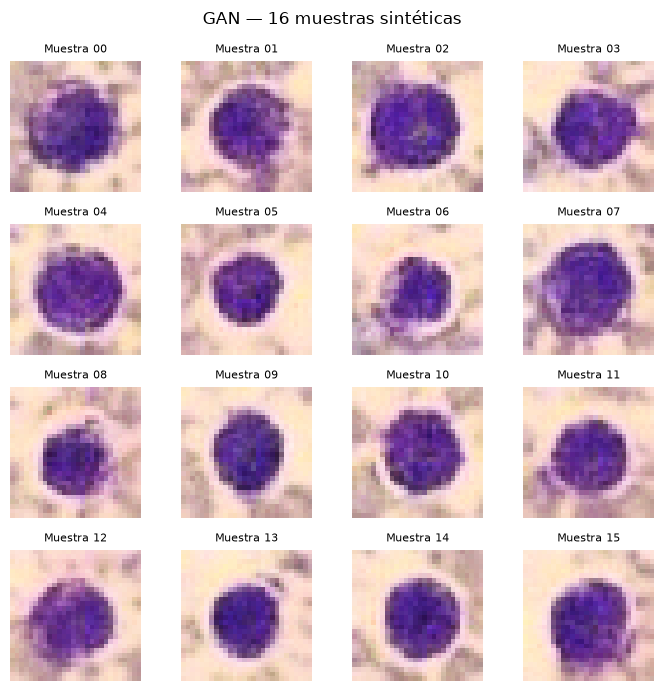

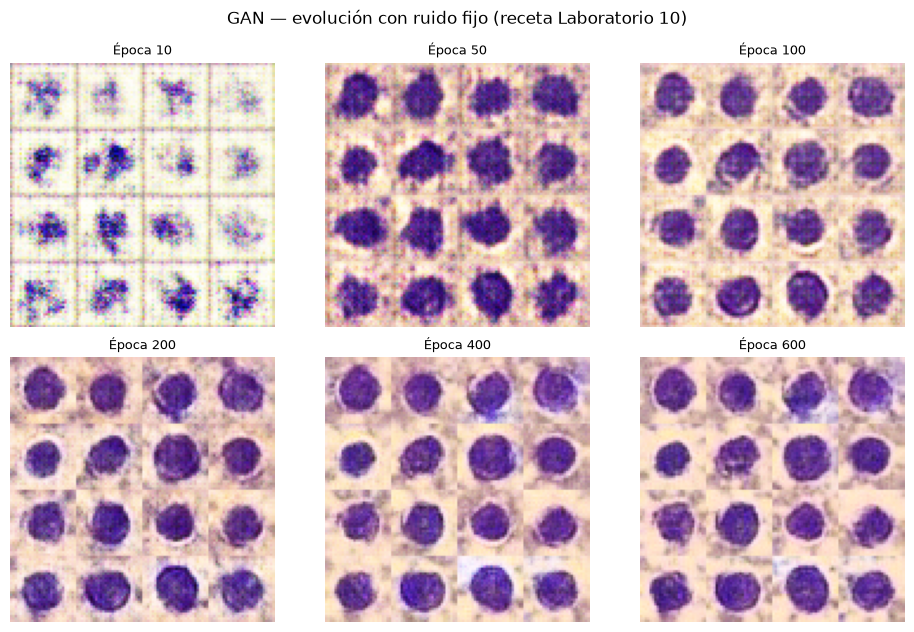

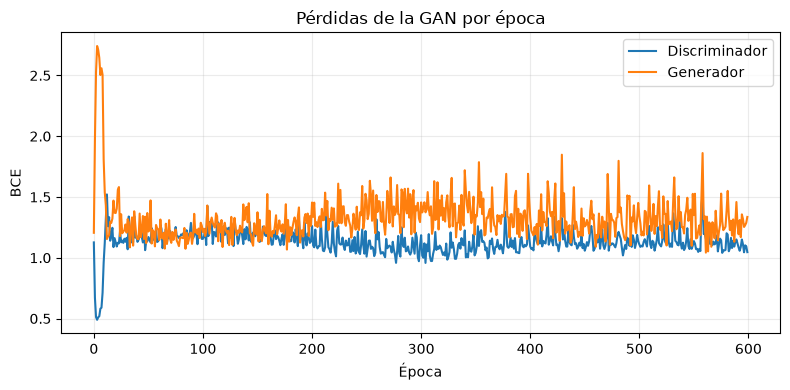

GAN: 300 PNG en 0.26s; entrenamiento=61.63s


In [11]:
modelo_gan_g, modelo_gan_d, metadata_gan, instantaneas_gan = entrenar_gan()
assert metadata_gan["cumple_limite_1200s"] and metadata_gan["tiempo_entrenamiento_gpu_segundos"] <= 1200.0
sincronizar_si_cuda()
inicio_gan_gen = time.perf_counter()
imagenes_gan_tensor = generar_gan(modelo_gan_g, 300, batch_size=64, seed=1003)
sincronizar_si_cuda()
tiempo_generacion_gan = time.perf_counter() - inicio_gan_gen
guardar_png_rgb(imagenes_gan_tensor, RUTA_GAN_IMG)
imagenes_gan_uint8 = cargar_png_rgb(RUTA_GAN_IMG)
cuadricula_uint8(imagenes_gan_uint8[:16], "GAN — 16 muestras sintéticas", "muestras_gan_eval.png")

def cuadricula_gan_uint8(imagenes):
    arreglo = np.asarray(imagenes[:16])
    return np.concatenate([
        np.concatenate([arreglo[fila + columna] for columna in range(4)], axis=1)
        for fila in range(0, 16, 4)
    ], axis=0)

if instantaneas_gan:
    epocas_snap = sorted(instantaneas_gan)
    columnas = 3
    filas = (len(epocas_snap) + columnas - 1) // columnas
    figura_ev, ejes_ev = plt.subplots(filas, columnas, figsize=(3.2 * columnas, 3.2 * filas), squeeze=False)
    for eje, epoca_snap in zip(ejes_ev.flat, epocas_snap):
        eje.imshow(cuadricula_gan_uint8(instantaneas_gan[epoca_snap][:16]))
        eje.set_title(f"Época {epoca_snap}", fontsize=9)
        eje.axis("off")
    for eje in ejes_ev.flat[len(epocas_snap):]:
        eje.axis("off")
    figura_ev.suptitle("GAN — evolución con ruido fijo (receta Laboratorio 10)")
    figura_ev.tight_layout()
    figura_ev.savefig(RUTA_GRAFICAS / "evolucion_gan.png", dpi=150, bbox_inches="tight")
    plt.show()

figura_gan, eje_gan = plt.subplots(figsize=(8, 4))
eje_gan.plot(metadata_gan["historial"]["perdida_d"], label="Discriminador")
eje_gan.plot(metadata_gan["historial"]["perdida_g"], label="Generador")
eje_gan.set(title="Pérdidas de la GAN por época", xlabel="Época", ylabel="BCE")
eje_gan.legend()
eje_gan.grid(alpha=0.25)
figura_gan.tight_layout()
figura_gan.savefig(RUTA_GRAFICAS / "perdida_gan.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"GAN: 300 PNG en {tiempo_generacion_gan:.2f}s; entrenamiento={metadata_gan['tiempo_entrenamiento_gpu_segundos']:.2f}s")

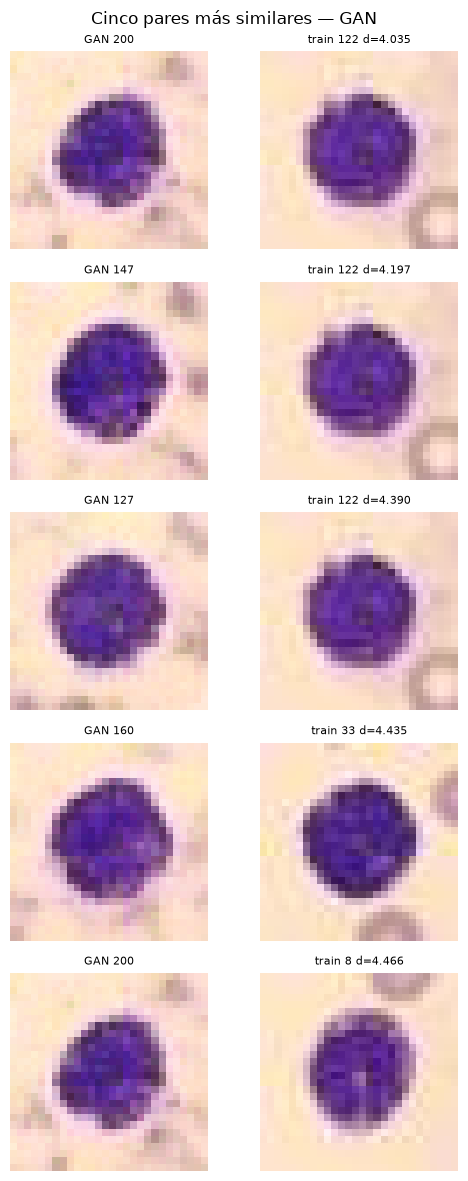

,fraccion_duplicados_exactos,concentracion_vecino_train,concentracion_clase_predicha,distancia_media_sintetica,ratio_diversidad_vs_mejor_base,indicios_colapso
VAE,0.0,0.053333,0.833333,6.495081,0.863604,True
DDPM,0.0,0.113333,0.526667,7.520903,1.0,False
GAN,0.0,0.056667,0.73,7.863175,1.04551,False


Indicios de colapso por modelo: {'VAE': True, 'DDPM': False, 'GAN': False}


In [12]:
metricas_generadores["modelos"]["GAN"] = evaluar_generador("GAN", imagenes_gan_uint8, tiempo_generacion_gan, None, "medido en esta ejecución")
predicciones_sinteticas["modelos"]["GAN"] = {"predicciones": predecir_cnn(modelo_cnn, imagenes_gan_uint8).tolist(), "n": 300}

def indicadores_colapso(nombre, imagenes_uint8, datos):
    filas = len(imagenes_uint8)
    unicos = len(np.unique(imagenes_uint8.reshape(filas, -1), axis=0))
    vecinos = np.asarray(datos["memorizacion"]["vecino_train_sinteticas"])
    conteo_vecinos = Counter(vecinos.tolist())
    conteo_clases = datos["clasificacion"]["conteo_por_indice"]
    return {
        "fraccion_duplicados_exactos": float(1.0 - unicos / filas),
        "concentracion_vecino_train": float(conteo_vecinos.most_common(1)[0][1] / filas),
        "concentracion_clase_predicha": float(max(conteo_clases.values()) / filas),
        "distancia_media_sintetica": float(datos["diversidad"]["media_sintetica"]),
    }

indicadores = {nombre: indicadores_colapso(nombre, imagenes, metricas_generadores["modelos"][nombre]) for nombre, imagenes in (
    ("VAE", imagenes_vae_uint8), ("DDPM", imagenes_ddpm_uint8), ("GAN", imagenes_gan_uint8)
)}
mejor_diversidad_base = max(indicadores["VAE"]["distancia_media_sintetica"], indicadores["DDPM"]["distancia_media_sintetica"])
for nombre, indicador in indicadores.items():
    indicador["ratio_diversidad_vs_mejor_base"] = float(indicador["distancia_media_sintetica"] / mejor_diversidad_base)
def tiene_indicios_colapso(indicador):
    return bool(
        indicador["fraccion_duplicados_exactos"] > 0.01
        or indicador["concentracion_vecino_train"] > 0.12
        or indicador["concentracion_clase_predicha"] > 0.80
        or indicador["ratio_diversidad_vs_mejor_base"] < 0.60
    )

for nombre_ind, indicador_ind in indicadores.items():
    indicador_ind["indicios_colapso"] = tiene_indicios_colapso(indicador_ind)
indicios_gan = bool(indicadores["GAN"]["indicios_colapso"])
metricas_generadores["bono_gan"] = {
    "entrenamiento": {clave: metadata_gan[clave] for clave in ("epocas", "actualizaciones", "tiempo_entrenamiento_gpu_segundos", "limite_gpu_segundos", "interrumpido_por_tiempo", "cumple_limite_1200s")},
    "indicadores_colapso": indicadores,
    "regla_colapso": "duplicados>0.01 o concentración del vecino train>0.12 o concentración de clase>0.80 o diversidad<0.60×la mejor base; se aplica a los tres generadores",
    "evidencia_visual": "cuadrícula muestras_gan_eval.png comparada con muestras_vae_eval.png y muestras_ddpm_eval.png, más evolucion_gan.png con ruido fijo (estilo Laboratorio 10)",
}
with open(RUTA_EVALUACION / "metricas_generadores.json", "w", encoding="utf-8") as archivo:
    json.dump(metricas_generadores, archivo, ensure_ascii=False, indent=2)
with open(RUTA_EVALUACION / "predicciones_sinteticas.json", "w", encoding="utf-8") as archivo:
    json.dump(predicciones_sinteticas, archivo, ensure_ascii=False, indent=2)
tabla_colapso = pd.DataFrame(indicadores).T
display(tabla_colapso.round(4))
print("Indicios de colapso por modelo:", {nombre: indicador["indicios_colapso"] for nombre, indicador in indicadores.items()})

### Colapso de modos y decisión final

El análisis de colapso combina cuatro evidencias cuantitativas —duplicados exactos, concentración en un mismo vecino de `train`, concentración de la clase predicha y diversidad relativa frente a la mejor base— con la inspección de las tres cuadrículas. Un generador con indicios de colapso no se elige para el aumento aunque su fracción de basófilos sea alta. La decisión final se guarda en `metricas_generadores.json` bajo `seleccion`.

In [13]:
CALIDAD_VISUAL["GAN"] = 0.20 if indicios_gan else 0.50
puntajes_finales = {nombre: puntuar_generador(nombre, datos) for nombre, datos in metricas_generadores["modelos"].items()}
elegibles = [nombre for nombre in puntajes_finales if not indicadores[nombre]["indicios_colapso"]]
GENERADOR_ELEGIDO = max(elegibles, key=lambda nombre: puntajes_finales[nombre]["puntaje"])
CAMBIA_POR_BONO = bool(GENERADOR_ELEGIDO != GENERADOR_PROVISIONAL)
datos_elegido = metricas_generadores["modelos"][GENERADOR_ELEGIDO]
justificacion = (
    f"Se elige {GENERADOR_ELEGIDO} con puntaje {puntajes_finales[GENERADOR_ELEGIDO]['puntaje']:.4f}. "
    f"Consistencia: fracción basófila {datos_elegido['clasificacion']['fraccion_basofilo']:.3f} frente al recall de referencia {RECALL_REFERENCIA:.3f}; "
    f"diversidad: {datos_elegido['diversidad']['media_sintetica']:.3f} frente a {datos_elegido['diversidad']['media_real']:.3f} en 100 basófilos reales; "
    f"memorización: vecino train de sintéticas {datos_elegido['memorizacion']['sinteticas']['media']:.3f} frente a test {datos_elegido['memorizacion']['test']['media']:.3f}; "
    f"costo: {datos_elegido['costo']['tiempo_generacion_300_s']:.3f} s para 300 imágenes. "
    f"Indicios de colapso por modelo={ {nombre: indicador['indicios_colapso'] for nombre, indicador in indicadores.items()} }; los modelos con indicios quedan excluidos. "
    "Las métricas son académicas y limitadas: la CNN evaluadora compartió los 200 basófilos con los generadores."
)
metricas_generadores["seleccion"] = {
    "generador": GENERADOR_ELEGIDO,
    "justificacion": justificacion,
    "cambia_por_bono": CAMBIA_POR_BONO,
    "seleccion_provisional": GENERADOR_PROVISIONAL,
    "puntajes": puntajes_finales,
    "pesos": PESOS_DECISION,
}
with open(RUTA_EVALUACION / "metricas_generadores.json", "w", encoding="utf-8") as archivo:
    json.dump(metricas_generadores, archivo, ensure_ascii=False, indent=2)
display(pd.DataFrame(puntajes_finales).T.round(4))
print("Generador elegido:", GENERADOR_ELEGIDO, "| cambia por el bono:", CAMBIA_POR_BONO)

,consistencia,diversidad,memorizacion,costo,calidad_visual,puntaje
VAE,0.1494,0.7927,0.8467,0.9774,0.45,0.6182
DDPM,0.1494,0.9179,0.9648,0.2776,0.85,0.7303
GAN,0.3652,0.9597,0.9895,0.8111,0.50,0.7489


Generador elegido: GAN | cambia por el bono: True


## Actividad 4. Clasificadores con sobremuestreo y aumento sintético

Se reutilizan las 300 PNG del generador elegido y se generan 352 adicionales con el mismo modelo y pasos de inferencia. Los tres conjuntos de entrenamiento tienen 11.307, 11.959 y 11.959 imágenes. `val` sigue usándose solo para EarlyStopping y `test` solo para evaluación. Las dos CNN nuevas usan `CNNReferencia` sin cambios, Adam `1e-3`, lote 128, máximo 10 épocas, EarlyStopping sobre `val_loss` con paciencia 3 y restauración de los mejores pesos; las semillas se reinician a 42 antes de cada entrenamiento.

In [14]:
from sklearn.metrics import confusion_matrix

RUTA_ADICIONALES = ARTEFACTOS_P2 / "imagenes_sinteticas_adicionales"
RUTA_ADICIONALES.mkdir(parents=True, exist_ok=True)
CARPETA_ADICIONALES = RUTA_ADICIONALES / GENERADOR_ELEGIDO.lower()
CARPETA_ADICIONALES.mkdir(parents=True, exist_ok=True)
SEMILLAS_ADICIONALES = {"VAE": 1301, "DDPM": 1302, "GAN": 1303}
semilla_adicional = SEMILLAS_ADICIONALES[GENERADOR_ELEGIDO]
if len(sorted(CARPETA_ADICIONALES.glob("*.png"))) == 352:
    imagenes_adicionales_uint8 = cargar_png_rgb(CARPETA_ADICIONALES, 352)
    print(f"Se reutilizan 352 PNG adicionales de {GENERADOR_ELEGIDO} en {CARPETA_ADICIONALES}.")
else:
    if GENERADOR_ELEGIDO == "VAE":
        tensor_adicional = generar_vae(modelo_vae, 352, batch_size=64, seed=semilla_adicional)
    elif GENERADOR_ELEGIDO == "DDPM":
        tensor_adicional = generar_ddpm(modelo_ddpm, 352, pasos_inferencia=PASOS_INFERENCIA_DDPM, batch_size=16, seed=semilla_adicional, scheduler=scheduler_ddpm)
    else:
        tensor_adicional = generar_gan(modelo_gan_g, 352, batch_size=64, seed=semilla_adicional)
    guardar_png_rgb(tensor_adicional, CARPETA_ADICIONALES)
    imagenes_adicionales_uint8 = cargar_png_rgb(CARPETA_ADICIONALES, 352)

if GENERADOR_ELEGIDO == "VAE":
    imagenes_base_uint8 = imagenes_vae_uint8
elif GENERADOR_ELEGIDO == "DDPM":
    imagenes_base_uint8 = imagenes_ddpm_uint8
else:
    imagenes_base_uint8 = imagenes_gan_uint8
sinteticas_652_uint8 = np.concatenate((imagenes_base_uint8, imagenes_adicionales_uint8), axis=0)
assert sinteticas_652_uint8.shape == (652, 28, 28, 3) and sinteticas_652_uint8.dtype == np.uint8
assert 300 + 352 == 652

idx_baso_sobremuestreo = np.resize(idx_sub, N)
idx_train_sobremuestreo = np.concatenate((idx_baso_sobremuestreo, idx_otros))
assert len(idx_train_sobremuestreo) == 11959
x_sobremuestreo = imagenes_a_tensor(train.imgs[idx_train_sobremuestreo], "cero_uno")
y_sobremuestreo = torch.as_tensor(train.labels.ravel()[idx_train_sobremuestreo], dtype=torch.long)
x_aumento = torch.cat((x_cnn, imagenes_a_tensor(sinteticas_652_uint8, "cero_uno")))
y_aumento = torch.cat((y_cnn, torch.zeros(652, dtype=torch.long)))
assert len(x_cnn) == 11307 and len(x_aumento) == 11959
print(f"Generador elegido={GENERADOR_ELEGIDO}; 300 reutilizadas + 352 adicionales (semilla {semilla_adicional}).")
print(f"Conjuntos: referencia={len(x_cnn)}, sobremuestreo={len(x_sobremuestreo)}, aumento={len(x_aumento)}")

def reiniciar_semillas_42():
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def entrenar_cnn_variante(nombre, x_entreno, y_entreno, config_adicional):
    ruta_checkpoint = RUTA_MODELOS / f"{nombre}.pt"
    config = {
        "semilla": 42, "entrada": [3, 28, 28], "normalizacion": "RGB [0,255] -> [0,1]",
        "arquitectura": cnn_config["arquitectura"], "optimizador": "Adam", "learning_rate": 1e-3,
        "batch_size": 128, "max_epocas": 10,
        "early_stopping": {"monitor": "val_loss", "patience": 3, "restaurar_mejores_pesos": True},
        "n_entrenamiento": int(len(x_entreno)), **config_adicional,
    }
    if ruta_checkpoint.exists():
        checkpoint = torch.load(ruta_checkpoint, map_location="cpu", weights_only=True)
        config_prev = checkpoint.get("config", {})
        if (config_prev.get("generador") == config["generador"]
                and config_prev.get("semilla_adicional") == config["semilla_adicional"]):
            modelo = CNNReferencia().to(DISPOSITIVO)
            modelo.load_state_dict(checkpoint["state_dict"])
            print(f"{nombre}: checkpoint recuperado; no se reentrena.")
            return modelo.eval(), checkpoint["historial"], checkpoint["epocas"], checkpoint["config"]
    reiniciar_semillas_42()
    loader_train = DataLoader(TensorDataset(x_entreno, y_entreno), batch_size=128, shuffle=True, generator=torch.Generator().manual_seed(42))
    loader_val = DataLoader(TensorDataset(x_val, y_val), batch_size=256, shuffle=False)
    modelo = CNNReferencia().to(DISPOSITIVO)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)
    historial = {"train_loss": [], "val_loss": []}
    mejor_val = float("inf")
    mejores_pesos = None
    sin_mejora = 0
    for epoca in range(10):
        modelo.train()
        suma_train = 0.0
        for xb, yb in loader_train:
            xb, yb = xb.to(DISPOSITIVO), yb.to(DISPOSITIVO)
            optimizador.zero_grad(set_to_none=True)
            perdida = F.cross_entropy(modelo(xb), yb)
            perdida.backward()
            optimizador.step()
            suma_train += perdida.item() * len(xb)
        modelo.eval()
        suma_val = 0.0
        with torch.no_grad():
            for xb, yb in loader_val:
                xb, yb = xb.to(DISPOSITIVO), yb.to(DISPOSITIVO)
                suma_val += F.cross_entropy(modelo(xb), yb, reduction="sum").item()
        train_loss = suma_train / len(loader_train.dataset)
        val_loss = suma_val / len(loader_val.dataset)
        historial["train_loss"].append(train_loss)
        historial["val_loss"].append(val_loss)
        print(f"{nombre} época {epoca + 1:02d}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}")
        if val_loss < mejor_val:
            mejor_val = val_loss
            mejores_pesos = copy.deepcopy(modelo.state_dict())
            sin_mejora = 0
        else:
            sin_mejora += 1
            if sin_mejora >= 3:
                print(f"{nombre}: EarlyStopping sin mejora durante 3 épocas.")
                break
    modelo.load_state_dict(mejores_pesos)
    torch.save({"state_dict": modelo.cpu().state_dict(), "historial": historial, "epocas": len(historial["train_loss"]), "config": config}, ruta_checkpoint)
    modelo.to(DISPOSITIVO)
    return modelo.eval(), historial, len(historial["train_loss"]), config

def evaluar_clasificador(modelo, y_true):
    y_pred = predecir_cnn(modelo, test.imgs)
    matriz = confusion_matrix(y_true, y_pred, labels=list(range(8)))
    return {
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_basofilo": float(f1_score(y_true == 0, y_pred == 0, zero_division=0)),
        "recall_basofilo": float(recall_score(y_true == 0, y_pred == 0, zero_division=0)),
        "matriz": matriz,
        "y_pred": y_pred,
    }

modelo_sob, historial_sob, epocas_sob, config_sob = entrenar_cnn_variante(
    "cnn_sobremuestreo", x_sobremuestreo, y_sobremuestreo,
    {"tipo_conjunto": "sobremuestreo", "basofilos_reales": N, "generador": None, "semilla_adicional": None},
)
modelo_aum, historial_aum, epocas_aum, config_aum = entrenar_cnn_variante(
    "cnn_aumento_sintetico", x_aumento, y_aumento,
    {"tipo_conjunto": "aumento_sintetico", "basofilos_reales": 200, "generador": GENERADOR_ELEGIDO, "semilla_adicional": semilla_adicional},
)
print("CNN nuevas listas; configuraciones con semilla 42 y arquitectura idéntica.")

Se reutilizan 352 PNG adicionales de GAN en /home/juanes/Tareas/9 Semestre/Analisis Deep learning/Talleres/Taller 4/artefactos/persona2/imagenes_sinteticas_adicionales/gan.


Generador elegido=GAN; 300 reutilizadas + 352 adicionales (semilla 1303).
Conjuntos: referencia=11307, sobremuestreo=11959, aumento=11959


cnn_sobremuestreo: checkpoint recuperado; no se reentrena.
cnn_aumento_sintetico: checkpoint recuperado; no se reentrena.
CNN nuevas listas; configuraciones con semilla 42 y arquitectura idéntica.


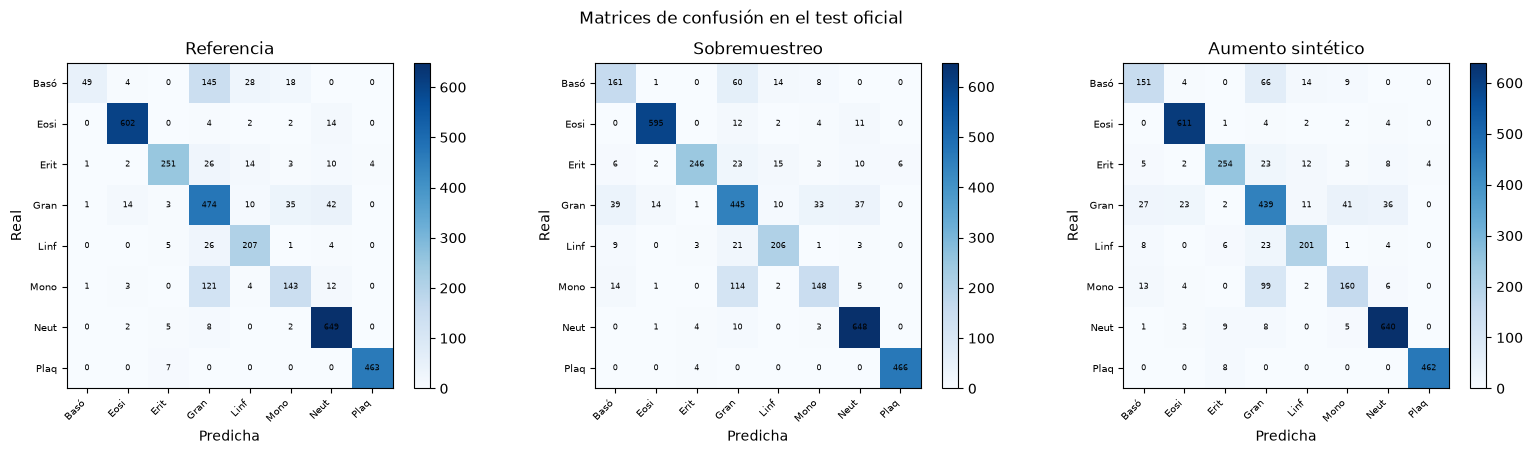

,F1 macro,F1 basófilo,Recall basófilo
Clasificador,,,
Referencia,0.769993,0.331081,0.200820
Sobremuestreo,0.823533,0.680761,0.659836
Aumento sintético,0.823654,0.672606,0.618852


Matrices (8,8) con sumas de fila verificadas: [244, 624, 311, 579, 243, 284, 666, 470]


In [15]:
y_true_test = test.labels.ravel().astype(np.int64)
conteo_test = np.bincount(y_true_test, minlength=8).tolist()
assert conteo_test == [244, 624, 311, 579, 243, 284, 666, 470]
evaluaciones_cnn = {
    "Referencia": evaluar_clasificador(modelo_cnn, y_true_test),
    "Sobremuestreo": evaluar_clasificador(modelo_sob, y_true_test),
    "Aumento sintético": evaluar_clasificador(modelo_aum, y_true_test),
}
for nombre_eval, evaluacion_eval in evaluaciones_cnn.items():
    assert evaluacion_eval["matriz"].shape == (8, 8)
    assert evaluacion_eval["matriz"].sum(axis=1).tolist() == conteo_test

metricas_clasificadores = {
    "test": {"n": int(len(y_true_test)), "conteo_por_clase": conteo_test, "clases": NOMBRES_CLASES},
    "generador_elegido": GENERADOR_ELEGIDO,
    "modelos": {},
    "y_true": y_true_test.tolist(),
}
for nombre_eval, evaluacion_eval in evaluaciones_cnn.items():
    metricas_clasificadores["modelos"][nombre_eval] = {
        "f1_macro": evaluacion_eval["f1_macro"],
        "f1_basofilo": evaluacion_eval["f1_basofilo"],
        "recall_basofilo": evaluacion_eval["recall_basofilo"],
        "matriz_confusion": evaluacion_eval["matriz"].tolist(),
        "y_pred": evaluacion_eval["y_pred"].tolist(),
        "historial": metricas_ref_json["historial"] if nombre_eval == "Referencia" else (historial_sob if nombre_eval == "Sobremuestreo" else historial_aum),
        "epocas": metricas_ref["epocas"] if nombre_eval == "Referencia" else (epocas_sob if nombre_eval == "Sobremuestreo" else epocas_aum),
        "config": config_ref_json["cnn"] if nombre_eval == "Referencia" else (config_sob if nombre_eval == "Sobremuestreo" else config_aum),
    }
with open(RUTA_EVALUACION / "metricas_clasificadores.json", "w", encoding="utf-8") as archivo:
    json.dump(metricas_clasificadores, archivo, ensure_ascii=False, indent=2)

figura_matrices, ejes_matrices = plt.subplots(1, 3, figsize=(16, 4.5))
for eje, (nombre_eval, evaluacion_eval) in zip(ejes_matrices, evaluaciones_cnn.items()):
    imagen_matriz = eje.imshow(evaluacion_eval["matriz"], cmap="Blues")
    eje.set_title(nombre_eval)
    eje.set_xlabel("Predicha")
    eje.set_ylabel("Real")
    eje.set_xticks(range(8), [nombre[:4] for nombre in NOMBRES_CLASES], rotation=45, ha="right", fontsize=7)
    eje.set_yticks(range(8), [nombre[:4] for nombre in NOMBRES_CLASES], fontsize=7)
    for fila_m in range(8):
        for columna_m in range(8):
            eje.text(columna_m, fila_m, str(evaluacion_eval["matriz"][fila_m, columna_m]), ha="center", va="center", fontsize=6)
    figura_matrices.colorbar(imagen_matriz, ax=eje, fraction=0.046)
figura_matrices.suptitle("Matrices de confusión en el test oficial")
figura_matrices.tight_layout()
figura_matrices.savefig(RUTA_GRAFICAS / "matrices_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

tabla_cnn = pd.DataFrame([
    {
        "Clasificador": nombre_eval,
        "F1 macro": evaluation_eval["f1_macro"],
        "F1 basófilo": evaluation_eval["f1_basofilo"],
        "Recall basófilo": evaluation_eval["recall_basofilo"],
    }
    for nombre_eval, evaluation_eval in evaluaciones_cnn.items()
]).set_index("Clasificador")
display(tabla_cnn.round(6))
print("Matrices (8,8) con sumas de fila verificadas:", conteo_test)

## Actividad 5. Análisis comparativo

### 1. Comparación de los modelos generativos

Las cuadrículas guardadas muestran regiones centrales violáceas de aspecto celular en los tres modelos, con bordes suaves y detalle citoplasmático limitado por la resolución 28×28. El VAE es más suavizado; DDPM y GAN conservan algo más de variación de forma y textura, y la GAN se volvió más uniforme al adoptar la inicialización del Laboratorio 10. La fracción de 300 sintéticas clasificadas como basófilo fue **0,03 para VAE y DDPM y 0,073 para GAN**, por debajo del recall **0,200820** de la CNN en basófilos reales de `test`. Como la CNN se entrenó con los mismos 200 basófilos usados por los generadores, el indicador mide consistencia según ese clasificador, no realismo biológico.

En diversidad (distancia euclidiana media en `[0,1]` sobre 100 muestras), el real dio **8,194**, VAE **6,495**, DDPM **7,521** y GAN **7,863**. En posible memorización, la distancia media al vecino más cercano entre los 200 basófilos de `train` fue **4,882** para VAE, **5,977** para DDPM y **5,827** para GAN, frente a **5,766** para los 244 basófilos reales de `test`; las tres escalas son comparables, sin señales claras de copia. El muestreo de 300 imágenes costó **0,023 s** para VAE, **12,487 s** para DDPM (50 pasos) y el valor exacto para GAN está en el JSON. La GAN se entrenó en **61,634 s de GPU** (600 épocas, 2.400 actualizaciones), dentro del límite de 1.200 s. No hubo duplicados exactos; el **5,7 %** de las sintéticas GAN compartió vecino de `train`, contra **11,3 %** en DDPM y **5,3 %** en VAE, y su concentración de clase predicha fue **73,0 %**. Según la ponderación documentada, GAN obtuvo el mayor puntaje y fue elegida para el aumento. La GAN sigue la receta del Laboratorio 10 adaptada a 28×28 (inicialización N(0,0.02), BatchNorm, suavizado 0.9 y snapshots con ruido fijo en `graficas/evolucion_gan.png`). El propio laboratorio advierte que la distancia de Fréchet no detecta memorización; por eso aquí se complementó con la distancia al vecino de `train`, más acorde con la pregunta del taller.

### 2. Utilidad de las imágenes sintéticas

La CNN con aumento sintético GAN mejoró respecto de la referencia (F1 macro **0,769993 → 0,823654**, F1 basófilo **0,331081 → 0,672606**, recall **0,200820 → 0,618852**) y quedó prácticamente a la par del sobremuestreo (**0,823533**, **0,680761**, **0,659836**), aunque este último conservó mayor F1 y recall de basófilo. Solo el **7,3 %** de las sintéticas GAN se clasificó como basófilo, por lo que parte del efecto puede provenir de regularización por ruido y no exclusivamente de información celular nueva. Con una sola semilla, 200 ejemplos de la clase minoritaria y métricas de píxeles, las diferencias no son estadísticamente confiables ni demuestran aporte de información nueva; hacen falta varias semillas, validación externa y revisión experta.

In [16]:
referencia_final = metricas_clasificadores["modelos"]["Referencia"]
sobre_final = metricas_clasificadores["modelos"]["Sobremuestreo"]
aumento_final = metricas_clasificadores["modelos"]["Aumento sintético"]
elegido_final = GENERADOR_ELEGIDO
datos_elegido_final = metricas_generadores["modelos"][elegido_final]
indicios_finales = {nombre: indicador["indicios_colapso"] for nombre, indicador in indicadores.items()}

NOTA_LABORATORIO = f"""Recomendamos complementar el entrenamiento con imágenes sintéticas solo como experimento controlado, no como sustituto validado de datos reales. En el test oficial de {len(y_true_test):,} imágenes, la CNN de referencia alcanzó F1 macro {referencia_final['f1_macro']:.6f}, F1 de basófilo {referencia_final['f1_basofilo']:.6f} y recall {referencia_final['recall_basofilo']:.6f}; con 652 sintéticas {elegido_final} mejoró a {aumento_final['f1_macro']:.6f}/{aumento_final['f1_basofilo']:.6f}/{aumento_final['recall_basofilo']:.6f}, mientras que el sobremuestreo de los 200 basófilos reales dio {sobre_final['f1_macro']:.6f}/{sobre_final['f1_basofilo']:.6f}/{sobre_final['recall_basofilo']:.6f} y conservó mejor F1 y recall de basófilo. Por tanto, conviene conservar las reales y tratar las generadas como apoyo, no como reemplazo al compartir entre instituciones.

Se eligió {elegido_final} porque su diversidad ({datos_elegido_final['diversidad']['media_sintetica']:.3f} frente a {datos_elegido_final['diversidad']['media_real']:.3f} en 100 basófilos reales), su distancia al vecino de entrenamiento ({datos_elegido_final['memorizacion']['sinteticas']['media']:.3f} frente a {datos_elegido_final['memorizacion']['test']['media']:.3f} en test) y su consistencia superaron a las alternativas según la ponderación documentada. Indicadores finales: {json.dumps(indicios_finales, ensure_ascii=False)}; el generador elegido no mostró indicios de colapso. Solo {datos_elegido_final['clasificacion']['fraccion_basofilo']:.1%} de sus sintéticas fue clasificado como basófilo, frente al recall {RECALL_REFERENCIA:.1%} en reales.

Limitaciones: una sola semilla, 200 basófilos de entrenamiento, imágenes de 28×28, CNN evaluadora entrenada con esos mismos 200 ejemplos y métricas de píxeles que no miden verosimilitud biológica ni privacidad. Se requieren múltiples semillas, revisión por expertos, validación externa multiinstitucional, pruebas de privacidad y evaluación clínica antes de cualquier uso asistencial. BloodMNIST es CC BY 4.0 (código MedMNIST Apache-2.0); citar MedMNIST v2, Ho et al., Goodfellow et al. y Radford et al."""
import re
palabras_nota = len(re.findall(r"\b[\wÁÉÍÓÚÜÑáéíóúüñ-]+\b", NOTA_LABORATORIO, flags=re.UNICODE))
assert palabras_nota <= 300, f"La nota tiene {palabras_nota} palabras"
(RUTA_EVALUACION / "nota_laboratorio.md").write_text(NOTA_LABORATORIO + "\n", encoding="utf-8")
print(f"Nota al laboratorio: {palabras_nota} palabras (límite 300).")
print(NOTA_LABORATORIO)

Nota al laboratorio: 248 palabras (límite 300).
Recomendamos complementar el entrenamiento con imágenes sintéticas solo como experimento controlado, no como sustituto validado de datos reales. En el test oficial de 3,421 imágenes, la CNN de referencia alcanzó F1 macro 0.769993, F1 de basófilo 0.331081 y recall 0.200820; con 652 sintéticas GAN mejoró a 0.823654/0.672606/0.618852, mientras que el sobremuestreo de los 200 basófilos reales dio 0.823533/0.680761/0.659836 y conservó mejor F1 y recall de basófilo. Por tanto, conviene conservar las reales y tratar las generadas como apoyo, no como reemplazo al compartir entre instituciones.

Se eligió GAN porque su diversidad (7.863 frente a 8.194 en 100 basófilos reales), su distancia al vecino de entrenamiento (5.827 frente a 5.766 en test) y su consistencia superaron a las alternativas según la ponderación documentada. Indicadores finales: {"VAE": true, "DDPM": false, "GAN": false}; el generador elegido no mostró indicios de colapso. Solo 7

### 3. Nota al laboratorio

La nota se genera en la celda siguiente, se guarda en `evaluacion/nota_laboratorio.md` y se verifica con un conteo automático de palabras. Incluye la recomendación, las tres comparaciones numéricas de clasificadores, la decisión de generador, las limitaciones, la licencia CC BY 4.0 y las referencias. Las conclusiones son académicas y no sustentan decisiones clínicas ni afirmaciones de privacidad.

In [17]:
import subprocess
import torchvision
import diffusers
import medmnist

def fmt(value, digits=6):
    return f"{float(value):.{digits}f}"

lineas_entrega = [
    "# Entrega de la persona 2 — Taller 4", "",
    "## Estado y entorno", "",
    "Completadas: actividad 3 (evaluación de generadores), bono GAN, decisión de generador, actividad 4 (tres CNN), actividad 5 (análisis y nota) y empaquetado. No se reentrenaron la CNN, el VAE ni el DDPM de persona 1: se cargaron sus checkpoints y se reutilizaron sus 300 PNG por modelo.", "",
    f"Ejecución: Python {__import__('sys').version.split()[0]}, PyTorch {torch.__version__}, torchvision {torchvision.__version__}, diffusers {diffusers.__version__}, MedMNIST {medmnist.__version__}, dispositivo {DISPOSITIVO}" + (f" ({torch.cuda.get_device_name(0)})" if DISPOSITIVO.type == "cuda" else "") + ".",
    "Directorio de trabajo: `Taller 4` (el notebook usa `Path.cwd()`). Para preservar `artefactos/persona1/`, las gráficas y recálculos de las celdas heredadas se redirigieron a `artefactos/persona2/auditoria/`; `idx_sub.npy` solo se verificó.", "",
    "## Actividad 3 y bono GAN", "",
    f"Reglas: primeras 100 PNG y primeros 100 basófilos de test para distancias; 300 sintéticas para clasificación y vecinos; 244 basófilos de test frente a los 200 de train para comparación de memorización. Recall de referencia: {RECALL_REFERENCIA!r}.", "",
    "| Generador | Fracción basófila | Diversidad sintética | Diversidad real | Cruzada | NN sintética media | NN test media | Tiempo 300 (s) |",
    "|---|---:|---:|---:|---:|---:|---:|---:|",
]
for nombre in ("VAE", "DDPM", "GAN"):
    datos = metricas_generadores["modelos"][nombre]
    lineas_entrega.append(f"| {nombre} | {fmt(datos['clasificacion']['fraccion_basofilo'], 3)} | {fmt(datos['diversidad']['media_sintetica'], 3)} | {fmt(datos['diversidad']['media_real'], 3)} | {fmt(datos['diversidad']['media_cruzada'], 3)} | {fmt(datos['memorizacion']['sinteticas']['media'], 3)} | {fmt(datos['memorizacion']['test']['media'], 3)} | {fmt(datos['costo']['tiempo_generacion_300_s'], 3)} |")
lineas_entrega += [
    "",
    f"Decisión: **{GENERADOR_ELEGIDO}** (provisional {GENERADOR_PROVISIONAL}, cambia por el bono={CAMBIA_POR_BONO}). Justificación completa en `evaluacion/metricas_generadores.json`, campo `seleccion`.",
    f"GAN DCGAN adaptada del Laboratorio 10 (inicialización N(0,0.02), snapshots con ruido fijo): {metadata_gan['epocas']} épocas, {metadata_gan['actualizaciones']} actualizaciones, {fmt(metadata_gan['tiempo_entrenamiento_gpu_segundos'], 3)} s de GPU (límite 1200 s, cumplido={metadata_gan['cumple_limite_1200s']}); Adam lr=2e-4, betas=(0.5,0.999), lote 64, semilla 42, etiquetas reales 0.9. Checkpoints e instantáneas en `modelos/gan/`.",
    "Indicadores de colapso aplicados a los tres modelos: " + json.dumps(metricas_generadores["bono_gan"]["indicadores_colapso"], ensure_ascii=False) + ".", "",
    "## Actividad 4", "",
    f"Generador elegido {GENERADOR_ELEGIDO}: 300 PNG reutilizadas + 352 adicionales (semilla {semilla_adicional}) en `imagenes_sinteticas_adicionales/{GENERADOR_ELEGIDO.lower()}/`. Conjuntos: 11.307 / 11.959 / 11.959 imágenes. CNN idénticas, Adam 1e-3, lote 128, 10 épocas máximo, EarlyStopping val_loss patience=3 con restauración, semilla 42 reiniciada por entrenamiento.", "",
    "| Clasificador | F1 macro | F1 basófilo | Recall basófilo |",
    "|---|---:|---:|---:|",
]
for nombre in ("Referencia", "Sobremuestreo", "Aumento sintético"):
    datos = metricas_clasificadores["modelos"][nombre]
    lineas_entrega.append(f"| {nombre} | {fmt(datos['f1_macro'])} | {fmt(datos['f1_basofilo'])} | {fmt(datos['recall_basofilo'])} |")
lineas_entrega += [
    "",
    "Matrices de confusión (8,8), y_true, y_pred e historiales: `evaluacion/metricas_clasificadores.json`; sumas de fila verificadas: [244, 624, 311, 579, 243, 284, 666, 470].", "",
    "## Archivos", "",
    "- `graficas/`: cuadrículas de evaluación, vecinos top 5, matrices de confusión, pérdida GAN y evolución GAN con ruido fijo.",
    "- `gan_imagenes/000.png..299.png` e `imagenes_sinteticas_adicionales/<generador>/000.png..351.png`.",
    "- `modelos/cnn_sobremuestreo.pt`, `modelos/cnn_aumento_sintetico.pt`, `modelos/gan/`.",
    "- `evaluacion/metricas_generadores.json`, `predicciones_sinteticas.json`, `metricas_clasificadores.json`, `nota_laboratorio.md`.",
    "- `auditoria/`: gráficas y recálculos de persona 1 redirigidos para no sobrescribir sus entregables.", "",
    "## Nota al laboratorio", "",
    NOTA_LABORATORIO, "",
    "## Referencias y límites", "",
    "BloodMNIST/MedMNIST: CC BY 4.0 para los datos; el código MedMNIST es Apache-2.0. Yang et al., *MedMNIST v2*, Scientific Data 10, 41 (2023), doi:10.1038/s41597-022-01721-8; Yang, Shi & Ni, ISBI 2021, doi:10.1109/ISBI48211.2021.9434062. DDPM con Hugging Face diffusers y Ho et al., NeurIPS 2020, arXiv:2006.11239. GAN: Goodfellow et al., NeurIPS 2014, y patrón DCGAN (Radford et al., ICLR 2016).",
    "Resultados académicos de una sola semilla y 200 basófilos; la CNN evaluadora compartió datos con los generadores. No se hacen afirmaciones clínicas ni de privacidad.", "",
]
(ARTEFACTOS_P2 / "ENTREGA_PERSONA2.md").write_text("\n".join(lineas_entrega) + "\n", encoding="utf-8")
print(f"Entrega persona 2 escrita: {ARTEFACTOS_P2 / 'ENTREGA_PERSONA2.md'}")

Entrega persona 2 escrita: /home/juanes/Tareas/9 Semestre/Analisis Deep learning/Talleres/Taller 4/artefactos/persona2/ENTREGA_PERSONA2.md


In [18]:
estado_git = subprocess.check_output(["git", "status", "--short"], cwd=RAIZ, text=True).strip().splitlines()
assert all("persona1" not in linea for linea in estado_git), "Hay cambios en artefactos de persona1"
for nombre_carpeta, cantidad in (("vae_imagenes", 300), ("ddpm_imagenes", 300)):
    assert len(sorted((ARTEFACTOS / nombre_carpeta).glob("*.png"))) == cantidad
assert len(sorted(RUTA_GAN_IMG.glob("*.png"))) == 300
assert len(sorted(CARPETA_ADICIONALES.glob("*.png"))) == 352
for nombre_modelo, datos_verif in metricas_generadores["modelos"].items():
    distancias_verif = [datos_verif["diversidad"][clave] for clave in ("media_sintetica", "media_real", "media_cruzada")]
    assert all(np.isfinite(valor) and valor >= 0 for valor in distancias_verif)
    top5_verif = datos_verif["memorizacion"]["top5"]
    assert len(top5_verif) == 5 and [par["distancia"] for par in top5_verif] == sorted(par["distancia"] for par in top5_verif)
    assert all(0 <= par["indice_referencia"] <= 199 for par in top5_verif)
    assert all(0 <= ind <= 199 for ind in datos_verif["memorizacion"]["vecino_train_sinteticas"])
    assert len(datos_verif["memorizacion"]["vecino_train_test"]) == 244
    assert sum(datos_verif["clasificacion"]["conteo_por_indice"].values()) == 300
for nombre_eval, datos_eval in metricas_clasificadores["modelos"].items():
    matriz_verif = np.asarray(datos_eval["matriz_confusion"])
    assert matriz_verif.shape == (8, 8) and matriz_verif.sum(axis=1).tolist() == conteo_test
assert metricas_clasificadores["modelos"]["Referencia"]["f1_macro"] == metricas_ref["f1_macro"]
assert metricas_clasificadores["modelos"]["Referencia"]["f1_basofilo"] == metricas_ref["f1_basofilo"]
assert metricas_clasificadores["modelos"]["Referencia"]["recall_basofilo"] == metricas_ref["recall_basofilo"]
assert metadata_gan["tiempo_entrenamiento_gpu_segundos"] <= 1200.0
assert palabras_nota <= 300
assert (ARTEFACTOS_P2 / "ENTREGA_PERSONA2.md").exists()
verificacion = pd.DataFrame([
    {"Verificación": "PNG base/GAN/adicionales", "Resultado": "300 + 300 + 300 + 352, RGB 28x28"},
    {"Verificación": "Distancias", "Resultado": "finitas y >= 0; top5 ordenado; índices en [0,199]"},
    {"Verificación": "Matrices de confusión", "Resultado": "(8,8) y sumas de fila correctas"},
    {"Verificación": "Métricas referencia", "Resultado": "idénticas a metricas_cnn.json"},
    {"Verificación": "Tiempo GAN", "Resultado": f"{metadata_gan['tiempo_entrenamiento_gpu_segundos']:.2f} s <= 1200 s"},
    {"Verificación": "Nota", "Resultado": f"{palabras_nota} palabras <= 300"},
    {"Verificación": "git status", "Resultado": "sin cambios en artefactos/persona1"},
]).set_index("Verificación")
display(verificacion)
print("Verificación final de artefactos y métricas: OK")
print("git status --short:")
print("\n".join(estado_git))

,Resultado
Verificación,
PNG base/GAN/adicionales,"300 + 300 + 300 + 352, RGB 28x28"
Distancias,"finitas y >= 0; top5 ordenado; índices en [0,199]"
Matrices de confusión,"(8,8) y sumas de fila correctas"
Métricas referencia,idénticas a metricas_cnn.json
Tiempo GAN,61.63 s <= 1200 s
Nota,248 palabras <= 300
git status,sin cambios en artefactos/persona1


Verificación final de artefactos y métricas: OK
git status --short:
M juan_alvarez_daniel_ortiz.ipynb
?? MINE_4210_ADL_202620_L10.ipynb
?? PLAN_IMPLEMENTACION.md
?? artefactos/persona2/
